# Ekstrakcija i analiza muzičkih elemenata iz audio signala - tutorijal


# 1. Uvod

Muzika je, u svojoj osnovi ustvari samo niz brojeva, odnosno uzoraka amplitude koji se, kada se pravilno reprodukuju kroz zvučnike, dovode u vibraciju vazduh i time proizvode zvuk koji čujemo. Iz te naizgled proste nizovne strukture moguće je, koristeći metode digitalne obrade signala i mašinskog učenja, izvući veoma bogat skup informacija: koji se instrumenti čuju u snimku, kojim tempom (BPM - Beats per Minute (BPM) predstavlja jedinicu za merenje tempa muzičke numere, odnosno broj ritmičkih otkucaja koji se javljaju tokom jednog minuta *(Fernández-Sotos et al., 2016; Vigl et al., 2024)*) je pesma odsvirana, u kom se tonalitetu nalazi, kao i koje konkretne note se u datom trenutku sviraju na pojedinačnom instrumentu. Cilj ovog rada je da na primeru pesme korak po korak demonstrira kompletan proces te analize, od učitavanja sirovog audio signala do vizuelizacije i reprodukcije prepoznatih muzičkih elemenata u realnom vremenu.

Rad je pisan tako da bude razumljiv čitaocu koji ima tehničko (programersko/inženjersko) predznanje, ali čije poznavanje muzičke teorije i fizike zvuka nije nužno duboko - svaki muzički i fizički koncept (frekvencija, amplituda, spektar, ton, tonalitet, itd.) biće ukratko objašnjen u trenutku kada se prvi put koristi, pre nego što se pređe na njegovu tehničku implementaciju.

### 1.1. Motivacija

Analiza audio signala ima široku primenu - od automatske transkripcije muzike (notne zapise generisane iz snimka), preko sistema za prepoznavanje pesama (poput [Shazam-a](https://www.shazam.com/)), do alata za muzičare koji žele da nauče basline ili melodiju neke pesme bez pristupa notnom materijalu. Poslednji slučaj je i konkretna praktična motivacija ovog rada: mogućnost da se, isključivo na osnovu audio snimka, automatski izdvoji linija basa ili vokala i prikaže korisniku koju notu treba da odsvira ili otpeva u datom trenutku, sinhronizovano sa reprodukcijom pesme.

### 1.2. Struktura audio signala i osnovni pojmovi

Zvuk je fizički fenomen koji nastaje oscilovanjem vazdušnog pritiska. Mikrofon tu promenu pritiska pretvara u električni signal, koji računar zatim **uzorkuje** (sample) - tj. u pravilnim vremenskim intervalima zabeleži trenutnu vrednost amplitude signala. Broj takvih zabeleženih vrednosti u jednoj sekundi zove se **frekvencija uzorkovanja** (*sample rate*, izražena u Hercima, Hz). Standardna frekvencija uzorkovanja za muziku (i CD format) je 44100 Hz, što znači da se svaka sekunda zvuka predstavlja pomoću 44100 brojeva. Ovom frekvencijom se, prema Nyquist–Shannon teoremi (Nyquist–Shannon teorema definiše da signal može biti potpuno rekonstruisan iz svojih uzoraka ukoliko je frekvencija uzorkovanja najmanje dva puta veća od najviše frekvencije prisutne u signalu *(Shannon, 1949)*) o uzorkovanju, mogu verno predstaviti sve frekvencije zvuka do 22050 Hz - što je više nego dovoljno da pokrije opseg čujnosti ljudskog uha (približno 20 Hz - 20 000 Hz).

**Amplituda** signala u datom trenutku odgovara intenzitetu (jačini) zvuka, odnosno veća amplituda znači glasniji zvuk. **Frekvencija** oscilovanja, s druge strane, određuje **visinu tona** (*pitch*) koji čujemo: brže oscilovanje vazdušnog pritiska (veća frekvencija) daje viši, tanji ton, a sporije oscilovanje (manja frekvencija) daje niži, dublji ton. Upravo je frekvencija ta veličina preko koje se, kao što će biti pokazano kasnije u radu, prepoznaju konkretne muzičke note.

### 1.3. Pregled koraka obrade

Analiza sprovedena u ovom radu podeljena je na sledeće logičke celine, koje čine i strukturu ostatka teksta:

1. **Priprema signala** - učitavanje audio fajla, standardizacija frekvencije uzorkovanja i normalizacija amplitude, kako bi svi naredni koraci radili nad predvidivim i konzistentnim ulazom.
2. **Analiza u frekvencijskom domenu** - primena *Short-Time Fourier Transform* (STFT - predstavlja metodu za analizu promena frekvencijskog sadržaja signala tokom vremena primenom Furijeove transformacije nad kratkim vremenskim segmentima signala *(Allen & Rabiner, 1977)*) transformacije radi dobijanja spektrograma, vizuelnog prikaza toga koje frekvencije su prisutne u signalu tokom vremena.
3. **Razdvajanje izvora zvuka (Source Separation)** - izdvajanje pojedinačnih instrumenata (bubnjevi, bas, vokali, ostali instrumenti) iz mešanog signala pesme, korišćenjem savremenog modela dubokog učenja **Demucs (Deep Extractor for Music Sources predstavlja model dubokog učenja namenjen razdvajanju pojedinačnih instrumenata iz mešanog audio signala (Défossez, 2021))**, kao i klasičnog signal-processing pristupa **HPSS** (Harmonic-Percussive Source Separation) iz Python-ove biblioteke librosa (Librosa je Python biblioteka namenjena analizi muzike i audio signala koja pruža implementacije brojnih algoritama iz oblasti analize muzike *(McFee et al., 2015)*).
4. **Ritmička analiza** - detekcija *onset*-a (Onset predstavlja trenutak početka novog zvučnog događaja, kao što je udar bubnja ili početak odsvirane note *(Böck et al., 2012)*) i procena tempa pesme izraženog u BPM-u (*beats per minute*, otkucaji u minuti).
5. **Harmonijska analiza** - računanje **chroma** obeležja, koja predstavljaju energiju svake od 12 muzičkih nota nezavisno od oktave u kojoj se nalazi, i koja predstavljaju osnovu za sve dalje harmonijske analize.
6. **Detekcija tonaliteta** - primena **Krumhansl–Schmuckler** (Krumhansl–Schmuckler algoritam određuje tonalitet pesme poređenjem distribucije prisutnih nota sa unapred definisanim profilima dur i mol tonaliteta (Krumhansl, 1990)) algoritma nad chroma obeležjima radi automatskog određivanja tonaliteta (npr. *C Major*, *A Minor*) pesme, kao i poređenje tačnosti tog određivanja u zavisnosti od toga da li se koristi cela pesma, izolovani instrumenti ili HPSS harmonijska komponenta.
7. **Prikaz nota u realnom vremenu** - kombinovanjem chroma obeležja i RMS energije (RMS (Root Mean Square) predstavlja statističku meru efektivne amplitude signala i često se koristi kao procena njegove trenutne glasnoće *(Smith, 2011)*), izdvajaju se konkretne note koje sviraju izolovani bas i vokali, koje se zatim, sinhronizovano sa reprodukcijom audio signala, prikazuju korisniku u obliku „Trenutna nota / Sledeća nota”.


Svaka od navedenih celina detaljno je objašnjena u odgovarajućem poglavlju ovog rada, uz obrazloženje motivacije iza svakog koraka, tumačenje parametara korišćenih funkcija, kao i interpretaciju dobijenih rezultata.

# 2. Priprema audio signala

Pre nego što se nad audio signalom mogu primeniti bilo kakve analitičke metode, potrebno je signal učitati u memoriju računara i dovesti ga u standardizovan, predvidiv oblik. U ovom poglavlju se objašnjava zašto je ta priprema neophodna i kako je sprovedena.

### 2.1. Učitavanje potrebnih biblioteka

Prva ćelija koda uvozi sve biblioteke koje se koriste u radu. Najvažnije su:

- **`librosa`** - specijalizovana Python biblioteka za analizu audio i muzičkih signala; ona obezbeđuje gotove implementacije svih ključnih algoritama korišćenih u ovom radu (STFT, chroma obeležja, detekcija tempa, HPSS, itd.), tako da nije potrebno te algoritme implementirati „od nule”.
- **`numpy`** - biblioteka za numeričke operacije nad nizovima (vektorima i matricama), koja se koristi za sve matematičke operacije nad uzorcima signala (NumPy omogućava efikasan rad sa višedimenzionalnim nizovima podataka *(Harris et al., 2020)*).
- **`matplotlib`** - biblioteka za crtanje grafika, korišćena za sve vizuelizacije u radu (talasni oblik signala, spektrogram, chroma prikaz, itd.).
- **`pandas`** - korišćena za tabelarni prikaz i poređenje numeričkih rezultata (npr. detektovanih tonaliteta i BPM vrednosti) (Pandas pruža strukture podataka za tabelarnu analizu *(McKinney, 2010)*).
- **`soundfile`** - biblioteka za čuvanje audio signala (numpy niza) nazad u `.wav` fajl na disku.
- **`torch`** i **`demucs`** - `torch` (PyTorch predstavlja biblioteku za razvoj modela dubokog učenja *(Paszke et al., 2019)*) je biblioteka za mašinsko učenje, a `demucs` je model dubokog učenja treniran specifično za razdvajanje muzičkih izvora zvuka (detaljnije objašnjen u poglavlju 4).


In [1]:
import os
import time
import librosa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
import torch
from demucs.pretrained import get_model
from demucs.apply import apply_model

### 2.2. Putanja do audio fajla

U ovoj ćeliji se definiše putanja do `.wav` fajla koji se analizira u nastavku rada. Za potrebe ovog tutorijala korišćena je pesma *Lady Gaga - Bad Romance*, ali princip koji je opisan u ostatku rada je opšti i primenjiv na bilo koji drugi audio snimak.

In [2]:
audio_path = './songs/pop/Lady Gaga - Bad Romance.wav'

### 2.3. Učitavanje audio fajla

Funkcija `librosa.load` čita `.wav` fajl sa diska i vraća dve vrednosti: `signal`, niz brojeva koji predstavlja amplitudu zvuka u svakom trenutku (uzorku), i `sr` (*sample rate*), frekvenciju uzorkovanja tog signala.

Prosleđena su dva važna parametra:

- **`sr=44100`** - bez obzira na to kojom je frekvencijom uzorkovanja originalni fajl snimljen, `librosa` će ga automatski **resample**-ovati (preuzorkovati) na 44100 Hz. Ovo je važno jer se u nastavku analize koriste apsolutne vrednosti frekvencije uzorkovanja (npr. pri određivanju veličine FFT prozora), pa je neophodno da svi audio fajlovi koji se obrađuju budu usklađeni na istu vrednost; u suprotnom bi se isti parametri obrade različito interpretirali za fajlove snimljene različitim frekvencijama uzorkovanja.
- **`mono=True`** - originalni snimak je stereo (ima levi i desni audio kanal, radi prostornog/stereo efekta pri slušanju). Za potrebe analize sadržaja (koje note, koji tempo, koji tonalitet), prostorna informacija stereo signala nije relevantna, pa se signal svodi na jedan (mono) kanal, čime će se, dodatno, prepoloviti količina podataka koju je potrebno obraditi u svakom narednom koraku, ubrzavajući celokupnu analizu.

In [3]:
signal, sr = librosa.load(
    path=audio_path,
    sr=44100,
    mono=True
)

**Napomena o standardizaciji frekvencije uzorkovanja i broja kanala.** Frekvenciju uzorkovanja od 44100 Hz standardizujemo, jer ona predstavlja industrijski standard (koristi se, između ostalog na audio CD-ovima) i jer garantuje da će 44100 brojčanih vrednosti odgovarati tačno jednoj sekundi zvuka, što olakšava sva dalja vremenska preračunavanja (npr. konverziju indeksa uzorka u sekunde).

Konverzija stereo signala u mono takođe pojednostavljuje **Short-Time Fourier Transformation (STFT)** analizu koja sledi u poglavlju 3 - STFT se po definiciji primenjuje na jednodimenzionalni (mono) niz uzoraka, pa bi stereo signal morao da se obrađuje kanal po kanal, što bi nepotrebno udvostručilo posao bez ikakvog dobitka za analizu sadržaja pesme.

### 2.4. Normalizacija signala

**Normalizacija** je postupak skaliranja vrednosti signala tako da se sve amplitude smeste u tačno određeni, unapred poznat opseg - u ovom slučaju, u interval $[-1, 1]$. Ovo se postiže deljenjem svakog uzorka signala sa apsolutnom vrednošću njegovog najvećeg uzorka (`np.max(np.abs(signal))`), čime se signal skalira tako da njegov najglasniji trenutak dostiže tačno amplitudu $1$ (ili $-1$), a svi ostali uzorci srazmerno manje vrednosti.

Normalizacija je važna iz dva razloga:

1. **Konzistentnost između različitih snimaka.** Audio fajlovi se često snimaju i produkuju sa različitim nivoima glasnoće (*loudness*). Bez normalizacije, isti algoritam bi na tiše snimljenoj pesmi mogao proizvesti drugačije (lošije) rezultate nego na glasnije snimljenoj, iako je muzički sadržaj identičan po svojoj prirodi. Normalizacija uklanja ovu razliku i svodi sve signale na zajednički, uporediv opseg.
2. **Numerička stabilnost.** Mnoge operacije koje slede u analizi (logaritamske konverzije u decibele, računanje energije, itd.) su numerički stabilnije i lakše se interpretiraju kada su vrednosti ulaza unutar predvidivog, ograničenog opsega.

In [4]:
signal = signal / np.max(np.abs(signal))

### 2.5. Prikaz osnovnih informacija o audio fajlu

Nakon učitavanja i normalizacije, korisno je proveriti osnovne parametre signala: frekvenciju uzorkovanja, ukupan broj uzoraka i trajanje pesme u sekundama (koje se dobija jednostavnim deljenjem broja uzoraka sa frekvencijom uzorkovanja - ukoliko imamo 44100 uzoraka u sekundi, onda broj uzoraka podeljen sa 44100 daje broj sekundi). Ova provera služi kao potvrda da je fajl ispravno učitan pre nego što se pređe na složenije korake analize.

In [5]:
print(f'Sample Rate: {sr} Hz')
print(f'Broj uzoraka: {len(signal)}')
print(f'Trajanje pesme: {round(len(signal) / sr, 2)} sekundi')

Sample Rate: 44100 Hz
Broj uzoraka: 13601792
Trajanje pesme: 308.43 sekundi


# 3. Analiza u frekvencijskom domenu - Short-Time Fourier Transformation

Signal koji je do sada korišćen (`signal`) predstavlja zvuk u **vremenskom domenu** - niz amplituda kroz vreme. Iz takvog prikaza je vizuelno gotovo nemoguće pročitati koje se frekvencije (tonovi) u datom trenutku čuju. Za tu svrhu potrebno je preći u **frekvencijski domen**, u kojem se signal prikazuje kroz to koliko energije nosi svaka frekvencija, umesto kroz amplitudu u vremenu.

Alat koji omogućava taj prelaz je **Fourierova transformacija** (*Fourier Transform*) - matematička operacija koja proizvoljan signal razlaže na zbir jednostavnih sinusoida različitih frekvencija, amplituda i faza. Intuitivno, Fourierova transformacija odgovara na pitanje: „Od kojih 'čistih tonova' (sinusoida) se sastoji ovaj složeni zvuk, i kojim intenzitetom je svaki od njih zastupljen?” *(Allen & Rabiner, 1977)*.

Problem klasične Fourierove transformacije je što ona, primenjena nad celim signalom odjednom, daje informaciju o tome koje frekvencije su prisutne u signalu *tokom celog trajanja*, ali gubi informaciju o tome *kada* se koja frekvencija javlja - a upravo je ta vremenska dimenzija ključna za muziku (npr. koji ton se svira u trećem taktu pesme). Rešenje ovog problema je **Short-Time Fourier Transform (STFT)**. Signal se deli na mnogo kratkih, međusobno preklapajućih segmenata (nazvanih *frame*-ovi ili prozori), i Fourierova transformacija se primenjuje zasebno na svaki od njih. Rezultat je dvodimenzionalna matrica u kojoj jedna osa predstavlja vreme (koji je frame u pitanju), a druga frekvenciju - čime se dobija uvid u to koje frekvencije su prisutne u signalu *u svakom trenutku*.

### 3.1. Parametri STFT transformacije

Pre samog izračunavanja STFT-a, definišu se dva ključna parametra:

- **`n_fft` (veličina FFT prozora)** - broj uzoraka signala koji se uzima u obzir pri jednom izračunavanju Fourierove transformacije. Veći `n_fft` daje precizniju (finiju) frekvencijsku rezoluciju. Moguće je razlikovati bliske frekvencije jedne od druge - ali po cenu grublje vremenske rezolucije, jer se transformacija računa nad dužim vremenskim isečkom signala. Ovo je poznato kao **kompromis između vremenske i frekvencijske rezolucije** (posledica principa neodređenosti u analizi signala), odnosno, ne mogu se istovremeno postići savršena precizna lokacija u vremenu i savršena precizna lokacija u frekvenciji. Vrednost `n_fft=2048` predstavlja uobičajen, balansiran izbor za analizu muzike pri frekvenciji uzorkovanja od 44100 Hz (odgovara prozoru od približno 46 milisekundi).
- **`hop_length` (veličina pomeraja između frame-ova)** - broj uzoraka za koji se prozor pomera pre svakog narednog izračunavanja transformacije. Manji `hop_length` znači da se prozori više preklapaju, što daje veću vremensku rezoluciju rezultata (više frame-ova po sekundi), ali i veću računsku i memorijsku cenu. Vrednost `hop_length=512` (tj. jedna četvrtina vrednosti `n_fft`) je standardan izbor koji obezbeđuje dovoljno gusto vremensko uzorkovanje rezultata bez prekomernog opterećenja.

In [6]:
n_fft = 2048
hop_length = 512

### 3.2. Izračunavanje STFT-a

Funkcija `librosa.stft` prima signal i gore definisane parametre, i vraća matricu **kompleksnih brojeva**. Za svaku kombinaciju (frekvencija, vremenski frame) dobija se jedan kompleksan broj čiji **moduo** (apsolutna vrednost) predstavlja intenzitet (energiju) te frekvencije u tom trenutku, a čiji **argument** (faza) nosi informaciju o fazi sinusoide - podatak koji je bitan za savršenu rekonstrukciju originalnog signala, ali koji se u analizi sadržaja pesme (visina tona, ritam, tonalitet) po pravilu ne koristi i stoga se u narednim koracima odbacuje.

In [7]:
stft = librosa.stft(
    signal,
    n_fft=n_fft,
    hop_length=hop_length
)

### 3.3. Dobijanje spektrograma

**Spektrogram** je vizuelni prikaz rezultata STFT transformacije, i predstavlja standardan način prikazivanja toga „koje frekvencije su prisutne u signalu kroz vreme”. Da bi se od kompleksne STFT matrice dobio spektrogram, sprovode se dva koraka:

1. **Uzimanje apsolutne vrednosti (modula)** kompleksnog broja u svakoj tački matrice (`np.abs(stft)`), čime se dobija samo intenzitet (energija) svake frekvencije, bez informacije o fazi koja nam nije potrebna.
2. **Konverzija u decibelnu (dB) skalu.** Ljudski sluh ne percipira glasnoću zvuka linearno, već približno logaritamski - razlika u glasnoći između vrlo tihog i srednje tihog zvuka nam je uočljivija nego jednaka apsolutna razlika između dva glasna zvuka. Decibelna skala je logaritamska mera koja bolje odgovara upravo toj ljudskoj percepciji glasnoće, i istovremeno „sabija” veoma širok raspon mogućih vrednosti energije (koji u linearnoj skali može obuhvatati više redova veličine) u prikladniji, lakše čitljiv opseg za vizuelizaciju. Parametar `ref=np.max` znači da se sve vrednosti izražavaju relativno u odnosu na najjači (najglasniji) deo signala, koji time dobija vrednost 0 dB, dok sve tiše komponente dobijaju negativne vrednosti u decibelima.

In [8]:
spectogram = np.abs(stft)

spectogram_db = librosa.amplitude_to_db(
    spectogram,
    ref=np.max
)

### 3.4. Vizuelizacija spektrograma

Konačno, spektrogram se prikazuje pomoću funkcije `librosa.display.specshow`, gde je horizontalna osa vreme, vertikalna osa frekvencija (prikazana u logaritamskoj skali, `y_axis='log'`, jer muzičke frekvencije po prirodi rastu eksponencijalno - svaka sledeća oktava odgovara duplo većoj frekvenciji, tako da logaritamski prikaz ravnomernije raspoređuje muzički relevantne frekvencije po vertikalnoj osi), a boja svake tačke predstavlja intenzitet (u dB) te frekvencije u tom trenutku. Toplije boje (crvena/žuta) predstavljaju veću energiju, dok hladnije boje (plava/ljubičasta) predstavljaju manju energiju ili tišinu. Ova vizuelizacija omogućava da se, prostim pogledom na grafik, uoče trenuci u pesmi u kojima dolazi do naglih promena u frekvencijskom sadržaju (npr. ulazak novog instrumenta ili udari bubnjeva) *(Slika 1)*.

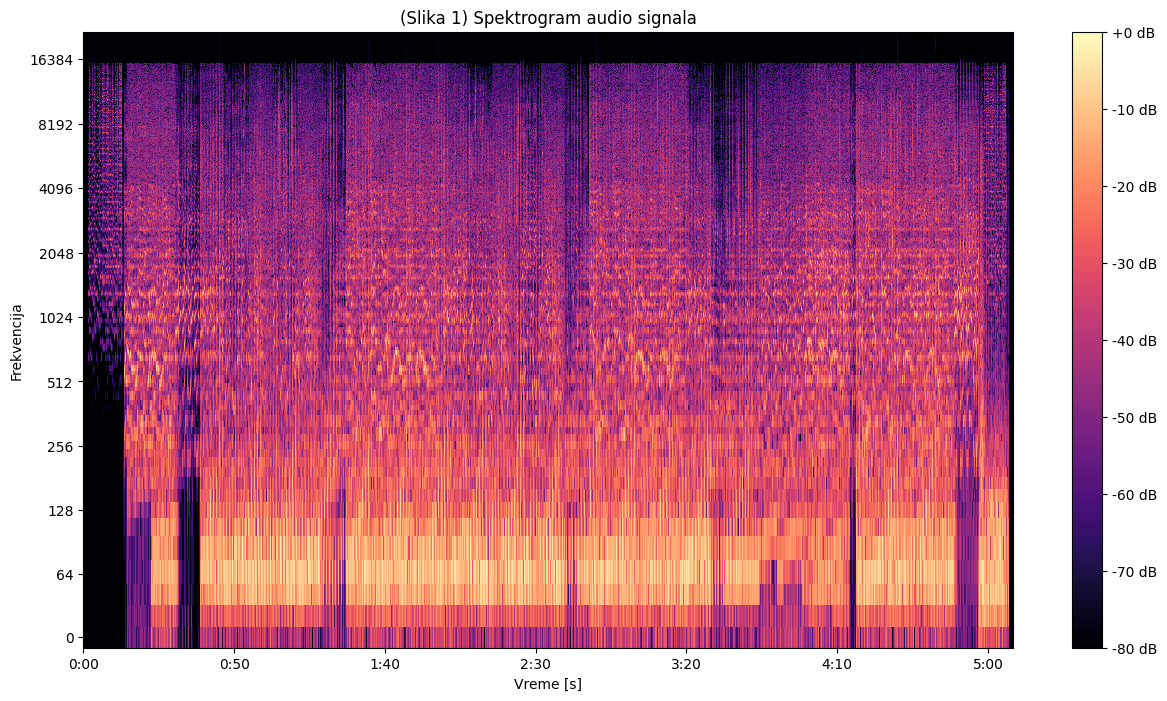

In [9]:
plt.figure(figsize=(15, 8))
librosa.display.specshow(
    spectogram_db,
    sr=sr,
    hop_length=hop_length,
    y_axis='log',
    x_axis='time'
)
plt.colorbar(format='%+2.0f dB')
plt.title("(Slika 1) Spektrogram audio signala")
plt.xlabel("Vreme [s]")
plt.ylabel("Frekvencija")
plt.show()

# 4. Razdvajanje izvora zvuka (Source Separation)

Snimljena pesma je *mešani* signal. Svi instrumenti (bubnjevi, bas, gitare, klavijature, vokali) su sabrani u jedan jedinstven audio talas. Za mnoge analize (npr. „koju notu svira bas u ovom trenutku?”) korisno je, ili čak neophodno, da se pojedinačni instrumenti prvo izdvoje iz te smeše. U ovom radu korišćena su dva fundamentalno različita pristupa tom problemu: savremeni pristup zasnovan na dubokom učenju (**Demucs**) i klasičan pristup zasnovan na obradi signala (Harmonic–Percussive Source Separation (HPSS) predstavlja algoritam za razdvajanje audio signala na harmonijsku komponentu, koja sadrži tonove i akorde, i perkusivnu komponentu, koja sadrži kratkotrajne ritmičke udare, kao što su bubnjevi i čineli *(Fitzgerald, 2010)*).

## 4.1. Demucs - razdvajanje pomoću dubokog učenja

**Demucs** (*Deep Extractor for Music Sources*) je model dubokog učenja koji je Facebook (Meta) AI Research razvio specifično za problem razdvajanja muzičkih izvora zvuka. Model je treniran na velikom broju parova (mešana pesma + pojedinačni instrumenti), i tokom treniranja je „naučio” da prepozna karakteristične akustičke obrasce svakog instrumenta (npr. tipičan frekvencijski i vremenski „potpis” udarca bas bubnja u odnosu na žičani bas), te da na osnovu njih razloži novu, do tada nepoznatu pesmu na njene sastavne komponente. Konkretno, korišćena verzija (`htdemucs`, *Hybrid Transformer Demucs* predstavlja unapređenu verziju Demucs modela koja kombinuje konvolutivne neuronske mreže i transformer arhitekturu radi preciznijeg razdvajanja audio izvora *(Défossez, 2021)*) je hibridni model koji kombinuje konvolutivne neuronske mreže (koje dobro hvataju lokalne, kratkotrajne akustičke obrasce) i transformer arhitekturu (koja dobro hvata dugoročne zavisnosti u signalu, poput ponavljajućih muzičkih fraza), i obrađuje signal istovremeno u vremenskom i u frekvencijskom domenu.

Za razliku od klasičnih metoda obrade signala, Demucs ne pretpostavlja unapred nikakva pravila o tome kako izgledaju pojedinačni instrumenti (npr. „bubnjevi su kratki i glasni udari”); umesto toga, sva ta znanja su implicitno naučena iz podataka tokom treniranja modela. Ovo mu omogućava znatno precizniju separaciju u odnosu na klasične metode, po cenu veće računske složenosti.

#### 4.1.1. Učitavanje Demucs modela

Funkcija `get_model(name='htdemucs')` preuzima (ili učitava iz lokalnog keša, ako je već preuzet) unapred istreniran `htdemucs` model. Pozivom `model.eval()` model se prebacuje u režim rada namenjen *inferenci* (korišćenju već istreniranog modela za predviđanje), za razliku od režima treniranja — u ovom režimu se isključuju mehanizmi koji se koriste samo tokom treniranja (kao što je *dropout*, nasumično „gašenje” dela neurona radi sprečavanja preprilagođavanja modela podacima), čime se obezbeđuje da model za isti ulaz uvek vrati identičan, deterministički izlaz.

Zatim se provera `torch.cuda.is_available()` koristi da se utvrdi da li je na raspoloživom računaru dostupna grafička kartica (GPU) sa CUDA podrškom (Compute Unified Device Architecture predstavlja platformu kompanije NVIDIA koja omogućava izvođenje paralelnih proračuna na grafičkim procesorima *(Nickolls et al., 2008)*). Ako je dostupna, model i svi podaci se prebacuju na GPU (`device='cuda'`), gde se operacije nad velikim matricama (na kojima se zasniva rad neuronskih mreža) izvršavaju značajno brže nego na procesoru (CPU), zahvaljujući masovnoj paralelizaciji koju GPU arhitektura omogućava. U suprotnom, obrada se izvršava na CPU-u (`device='cpu'`), što je sporije, ali funkcionalno jednako ispravno.

In [10]:
model = get_model(name='htdemucs')
model.eval()

device = 'cuda' if torch.cuda.is_available() else 'cpu'
model.to(device)

print(f'Demucs model je učitan: {device}')

Demucs model je učitan: cpu


#### 4.1.2. Priprema audio signala za Demucs model

Za razliku od prethodnih analiza gde je korišćen mono signal, Demucs model je treniran i radi nad **stereo** (dvokanalnim) signalom, jer prostorna (stereo) informacija, npr. činjenica da su vokali često mešani na sredini stereo slike, a pojedini instrumenti pomereni ka levom ili desnom kanalu, modelu pomaže da preciznije razdvoji izvore. Zbog toga se audio fajl ovde ponovo učitava, ali sa parametrom `mono=False`, čime se čuvaju oba (levi i desni) kanala.

Ukoliko bi originalni fajl ipak bio mono (`wav.ndim == 1`, tj. niz ima samo jednu dimenziju), on se veštački duplira u dva identična kanala (`np.stack([wav, wav])`) kako bi ulazni oblik podataka bio usklađen sa formatom koji model očekuje (uvek dva kanala).

Nakon toga se numpy niz konvertuje u PyTorch tenzor (`torch.tensor`), prebacuje na isti uređaj (CPU ili GPU) na kom se nalazi i sam model, i na kraju mu se dodaje dodatna dimenzija (`unsqueeze(0)`). Ova poslednja operacija je neophodna jer Demucs (kao i većina modela dubokog učenja) očekuje ulaz organizovan u **batch-eve** (grupe). Čak i kada se obrađuje samo jedan audio fajl, on mora biti predstavljen kao „batch veličine 1”, odnosno mora imati dodatnu, prvu dimenziju koja predstavlja broj fajlova u batch-u.

In [11]:
wav, sr = librosa.load(path=audio_path, sr=44100, mono=False)

if wav.ndim == 1:
    wav = np.stack([wav, wav])

wav = torch.tensor(wav, dtype=torch.float32)
wav = wav.to(device)

wav = wav.unsqueeze(0)

#### 4.1.3. Primena modela i podela na instrumente

U ovoj ćeliji se sprovodi sam proces razdvajanja. Prvo se kreira izlazni direktorijum (`./separated/<naziv pesme>`) u kome će razdvojeni instrumenti biti sačuvani.

Centralni deo ćelije je poziv `apply_model(model, wav)`, koji nad učitanim stereo signalom (`wav`) primenjuje Demucs model i vraća **četiri odvojena audio signala**, jedan za svaki od instrumenata na koje je model treniran da razdvaja pesmu: **`drums`** (bubnjevi/perkusije), **`bass`** (bas), **`vocals`** (vokali) i **`other`** (svi ostali instrumenti koji ne spadaju u prethodne tri kategorije, kao što su: gitare, klavijature, sintisajzeri, itd.). Poziv je obavijen blokom `with torch.no_grad():`, koji govori PyTorch-u da tokom izvršavanja ne treba da računa i pamti gradijente (izvode) potrebne za treniranje modela, pošto se model ovde samo *koristi*, a ne trenira, ovo značajno smanjuje potrošnju memorije i ubrzava izvršavanje.

Rezultat (`sources`) ima dodatnu *batch* dimenziju (zbog `unsqueeze(0)` iz prethodne ćelije), koja se uklanja pristupom `sources[0]`. Zatim se, za svaki od četiri instrumenta (`source_names`), odgovarajući signal:

1. prebacuje sa GPU-a nazad na CPU i konvertuje iz PyTorch tenzora u numpy niz (`.cpu().numpy()`), jer biblioteke za čuvanje i daljnju analizu audio fajlova (`soundfile`, `librosa`) rade sa numpy nizovima, a ne sa PyTorch tenzorima;
2. transponuje (`np.transpose`) kako bi oblik niza (broj uzoraka x broj kanala) bio usklađen sa formatom koji funkcija za čuvanje `sf.write` očekuje;
3. čuva na disk kao poseban `.wav` fajl (npr. `Bad Romance_bass.wav`), radi mogućnosti kasnijeg preslušavanja ili ponovne upotrebe bez potrebe za ponovnim pokretanjem (računski skupog) modela;
4. dodaje u Python rečnik `separated`, koji omogućava da se u svim narednim ćelijama ovog rada svakom instrumentu pristupi jednostavno po njegovom imenu (npr. `separated['bass']`).

Rezultujući signali u rečniku `separated` su **stereo** (imaju dve kolone/kanala), jer je to format u kome ih Demucs model generiše. Ova činjenica je relevantna za sve naredne ćelije koje ove signale koriste, jer će ih tamo biti potrebno prvo svesti na mono, na isti način kao što je to učinjeno sa originalnim signalom pesme u poglavlju 2.

In [12]:
output_root = './separated'
os.makedirs(output_root, exist_ok=True)

file_name = os.path.splitext(os.path.basename(audio_path))[0]

song_folder = os.path.join(output_root, file_name)
os.makedirs(song_folder, exist_ok=True)

print(f'{song_folder} folder je kreiran.\n')

start_time = time.time()
with torch.no_grad():
    sources = apply_model(model, wav)
finish_time = time.time() - start_time

print(f'[{round(finish_time, 2)}s]: Podela na instrumente je završena.')

sources = sources[0]
source_names = ['drums', 'bass', 'other', 'vocals']

separated = {}

for i, name in enumerate(source_names):
    audio = sources[i].cpu().numpy()

    audio = np.transpose(audio)

    path = os.path.join(song_folder, f'{file_name}_{name}.wav')
    sf.write(path, audio, sr)

    separated[name] = audio

    print(f'Sačuvano: {path}')

./separated\Lady Gaga - Bad Romance folder je kreiran.

[192.73s]: Podela na instrumente je završena.
Sačuvano: ./separated\Lady Gaga - Bad Romance\Lady Gaga - Bad Romance_drums.wav
Sačuvano: ./separated\Lady Gaga - Bad Romance\Lady Gaga - Bad Romance_bass.wav
Sačuvano: ./separated\Lady Gaga - Bad Romance\Lady Gaga - Bad Romance_other.wav
Sačuvano: ./separated\Lady Gaga - Bad Romance\Lady Gaga - Bad Romance_vocals.wav


## 4.2. HPSS - klasična podela na harmonijsku i perkusivnu komponentu

Za razliku od Demucs-a, koji je model dubokog učenja treniran da prepozna konkretne instrumente, **HPSS** (*Harmonic-Percussive Source Separation*) je klasičan, matematički (a ne naučen) algoritam koji ne razlikuje instrumente po njihovom identitetu, već signal deli na dve komponente prema **prirodi zvuka** koji proizvode *(Fitzgerald, 2010)*:

- **Harmonijska komponenta** obuhvata zvukove koji imaju stabilnu, jasno definisanu visinu tona koja se održava kroz duži vremenski period. U spektrogramu se takvi zvuci vide kao horizontalne, vodoravne linije (energija se koncentriše na istim frekvencijama tokom vremena). Tipičan primer su održani tonovi gitare, klavira, vokala ili bas linije.
- **Perkusivna komponenta** obuhvata kratke, naglašene udare bez jasne, održive visine tona. U spektrogramu se prikazuju kao vertikalne linije (energija se u kratkom vremenskom trenutku javlja na širokom rasponu frekvencija istovremeno, a zatim brzo nestaje). Tipičan primer su udari bubnjeva i čineli.

Algoritam ovu podelu sprovodi primenom **medijan filtriranja** nad spektrogramom signala, odnosno, jednom horizontalno (kroz vreme, na fiksnoj frekvenciji), čime se izdvaja harmonijska komponenta (jer medijan filtriranje potiskuje kratkotrajne, naglašene promene, a čuva postojane vrednosti), a jednom vertikalno (kroz frekvenciju, u fiksnom trenutku), čime se izdvaja perkusivna komponenta (jer se tako potiskuju vrednosti koje su postojane kroz vreme, a čuvaju kratki, široki udari). Za razliku od Demucs-a, HPSS ne prepoznaje *koji* je instrument u pitanju već samo *kakav tip* zvuka (održan ton naspram udara) instrument proizvodi, i zato ne može npr. odvojiti bas od vokala (oba su harmonijski), ali može odvojiti bubnjeve (perkusivno) od svih ostalih instrumenata (harmonijski) i to bez potrebe za GPU-om ili unapred istreniranim modelom, gotovo trenutno.

In [13]:
start_time = time.time()
harmonic_signal, percussive_signal = librosa.effects.hpss(signal)
finish_time = time.time() - start_time

print(f'[{round(finish_time, 2)}s]: HPSS podela je završena.')

harmonic_signal = harmonic_signal / np.max(np.abs(harmonic_signal))
percussive_signal = percussive_signal / np.max(np.abs(percussive_signal))

[41.53s]: HPSS podela je završena.


Nakon izračunavanja, obe komponente se ponovo normalizuju (na isti način i iz istog razloga kao u poglavlju 2.4) kako bi bile spremne za dalju upotrebu u analizama koje slede.

### 4.2.1. Vizuelizacija HPSS komponenti

Radi provere ispravnosti razdvajanja, obe komponente se prikazuju u **talasnom obliku** (*waveform*), grafika koji na horizontalnoj osi prikazuje vreme, a na vertikalnoj trenutnu amplitudu signala. Na ovim grafikonima je često vizuelno uočljivo da harmonijska komponenta ima glatkiji, postojaniji oblik amplitude (usled održanih tonova), dok perkusivna komponenta ima karakteristične nagle, kratke skokove amplitude koji odgovaraju udarima bubnjeva *(Slika 2 i Slika 3)*.

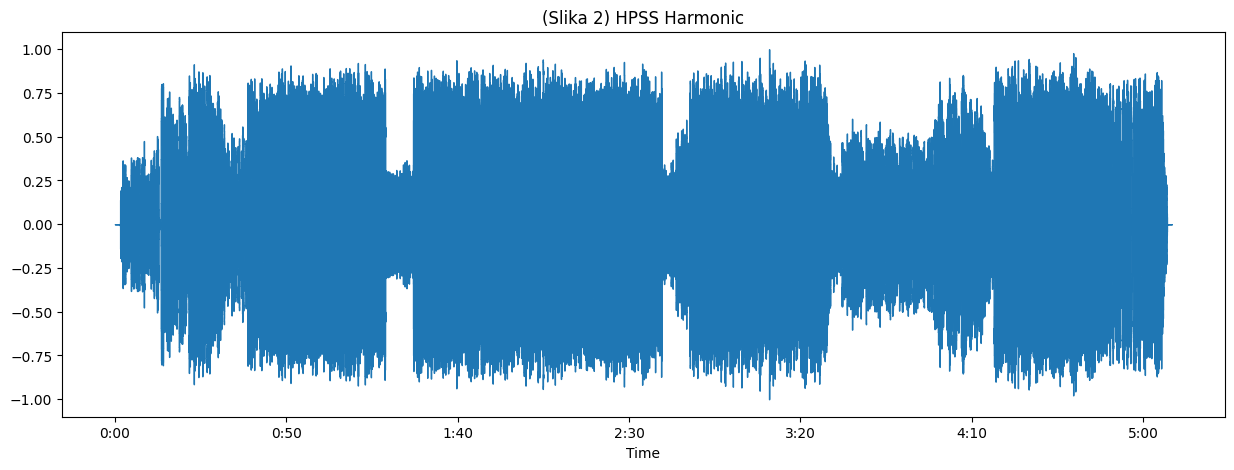

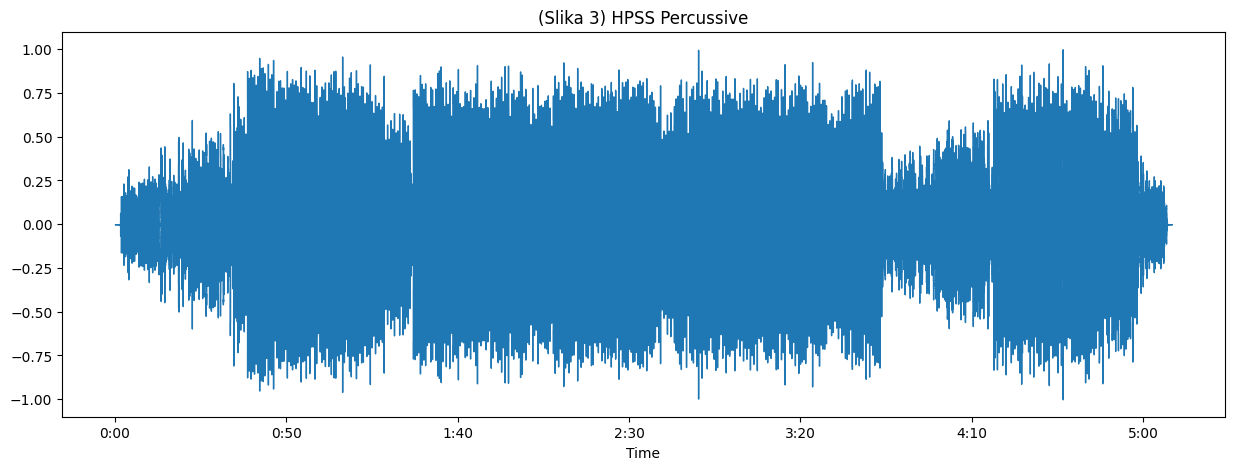

In [14]:
plt.figure(figsize=(15, 5))
librosa.display.waveshow(harmonic_signal, sr=sr)
plt.title('(Slika 2) HPSS Harmonic')
plt.show()

plt.figure(figsize=(15, 5))
librosa.display.waveshow(percussive_signal, sr=sr)
plt.title('(Slika 3) HPSS Percussive')
plt.show()

# 5. Ritmička analiza - Onset detekcija i procena tempa (BPM)

Nakon što su izolovani pojedinačni instrumenti, moguće je preći na analizu **ritma** pesme - konkretno, na određivanje tempa, izraženog u **BPM-u**. Ova analiza se sprovodi u dva koraka: prvo se detektuju svi *onset*-i), a zatim se, na osnovu njihove periodičnosti (učestalosti ponavljanja), procenjuje tempo.

## 5.1. Priprema izolovanih bubnjeva

Za detekciju ritma, poseban značaj imaju bubnjevi, jer upravo oni po pravilu najjasnije markiraju ritmički puls pesme. Izolovani signal bubnjeva (`separated['drums']`, dobijen Demucs separacijom u poglavlju 4.1) se ovde, na isti način kao i signal pesme u poglavlju 2, svodi na mono kanal (prosekom levog i desnog kanala) i normalizuje, čime se dobija konzistentan ulaz za dalju analizu.

In [15]:
drums_signal = separated['drums']
drums_signal = np.mean(drums_signal, axis=1)
drums_signal = drums_signal / np.max(np.abs(drums_signal))

## 5.2. Detekcija Onset-a

**Onset** predstavlja trenutak u signalu u kojem započinje novi, naglašen zvučni događaj,  npr. trenutak udara bubnja, trenutak otpočinjanja nove note na gitari, ili početak pevanja nove reči. Funkcija `librosa.onset.onset_strength` interno ponovo primenjuje STFT transformaciju (opisanu u poglavlju 3) nad prosleđenim signalom, i zatim, frame po frame, upoređuje spektar (frekvencijski sadržaj) trenutnog frame-a sa spektrom prethodnog. Rezultat je jednodimenzionalni niz (**onset strength envelope** - predstavlja vremensku funkciju koja opisuje intenzitet promena u spektru audio signala i koristi se kao osnova za detekciju ritmičkih događaja *(Böck et al., 2012)*)  u kome velika vrednost u datom trenutku znači da se spektar signala u tom trenutku naglo i značajno promenio (što tipično odgovara pojavi novog zvučnog događaja, npr. udara), dok mala vrednost znači da je spektar signala relativno stabilan (bez novih zvučnih događaja u tom trenutku).

U kodu se ova analiza sprovodi zasebno nad tri različita signala: nad **celom pesmom** (`signal`), nad **izolovanim bubnjevima** (`drums_signal`) i nad **HPSS perkusivnom komponentom** (`percussive_signal`), kako bi u narednom koraku (detekcija BPM-a) mogli da se uporede rezultati dobijeni na osnovu različitih ulaza, i da se proceni koji od njih daje najpouzdaniju procenu tempa.

In [16]:
onset_env_song = librosa.onset.onset_strength(
    y=signal,
    sr=sr
)

onset_env_drums = librosa.onset.onset_strength(
    y=drums_signal,
    sr=sr
)

onset_env_hpss = librosa.onset.onset_strength(
    y=percussive_signal,
    sr=sr
)

## 5.3. Detekcija tempa (BPM)

Na osnovu prethodno izračunatog *onset strength envelope*-a, funkcija `librosa.beat.beat_track` analizira njegovu **periodičnost**, odnosno, traži obrazac ponavljanja naglašenih vrednosti u približno jednakim vremenskim razmacima i na osnovu njega procenjuje **dominantan tempo** pesme (`tempo`), kao i tačne pozicije (indekse frame-ova) svakog pojedinačnog udara (`beat_frames`).

**Potencijalni problem: half-time i double-time** (Half-time i double-time predstavljaju česte greške u automatskoj proceni tempa, pri kojima algoritam detektuje tempo koji je dva puta manji ili dva puta veći od stvarnog tempa numere *(Peeters, 2007)*). Periodičnost ritma se objektivno može ispravno detektovati na više hijerarhijskih nivoa istovremeno; na primer, u pesmi čiji je „prirodan”, muzičarima intuitivan tempo 70 BPM, algoritam može jednako matematički opravdano detektovati periodičnost i na 140 BPM (dvostruko brže, *double-time*, ako se npr. akcentuju i parni i neparni udari) ili na 35 BPM (dvostruko sporije, *half-time*). Ovo je poznat i teško izbežan problem u automatskoj detekciji tempa. U ovom radu se pokušava delimično zaobići poređenjem detekcije nad tri različita signala (cela pesma, izolovani bubnjevi, HPSS perkusivna komponenta). Ideja je da je tempo detektovan direktno nad izolovanim bubnjevima, gde ne postoji „šum” u vidu drugih instrumenata koji bi mogli lažno naglasiti pogrešan ritmički nivo, po pravilu pouzdaniji.

In [20]:
df = pd.read_csv('new_results.csv')
song_file_name = file_name + ".wav"
song_details = df[df['song_name'] == song_file_name]
correct_bpm = int(song_details['manual_bpm'].iloc[0])

In [21]:
tempo_song, beat_frames_song = librosa.beat.beat_track(
    onset_envelope=onset_env_song,
    sr=sr
)

tempo_drums, beat_frames_drums = librosa.beat.beat_track(
    onset_envelope=onset_env_drums,
    sr=sr
)

tempo_hpss, beat_frames_hpss = librosa.beat.beat_track(
    onset_envelope=onset_env_hpss,
    sr=sr
)

tempo_song = round(tempo_song[0], 2)
tempo_drums = round(tempo_drums[0], 2)
tempo_hpss = round(tempo_hpss[0], 2)

data = {'Detected on:': ['Correct BPM', 'Song', 'Isolated drums', 'HPSS percussive'],
        'BPM:': [correct_bpm, tempo_song, tempo_drums, tempo_hpss]}

bpm_df = pd.DataFrame(data)
bpm_df

,Detected on:,BPM:
0,Correct BPM,120.00
1,Song,120.19
2,Isolated drums,120.19
3,HPSS percussive,120.19


U rezultujućoj tabeli poredi se detektovani BPM za sva tri signala. Vrednosti detektovane na celoj pesmi i na izolovanim bubnjevima su često identične ili veoma slične (jer bubnjevi po pravilu dominiraju ritmičkim sadržajem cele pesme), dok se procena dobijena preko HPSS perkusivne komponente povremeno razlikuje, usled toga što HPSS, za razliku od Demucs-a, nije specifično treniran da prepoznaje bubnjeve, te njegova perkusivna komponenta može sadržati i druge naglašene, kratke zvučne događaje (npr. udarce po žicama gitare) koji mogu iskriviti detekciju periodičnosti.

Kao što je gore obrazloženo, u nastavku rada koristi se **BPM detektovan na izolovanim bubnjevima** (`tempo_drums`, `beat_frames_drums`), jer se ta procena smatra najpouzdanijom osnovom za dalju vizuelizaciju ritma, iako se, kako je i navedeno, u praksi često poklapa sa BPM-om detektovanim na celoj pesmi.

## 5.4. Konverzija frame-ova u vreme

Pozicije detektovanih udara (`beat_frames_drums`) su izražene kao indeksi STFT frame-ova, a ne kao stvarno vreme u sekundama. Ovo je posledica toga što se ceo proces (onset detekcija, beat tracking) interno odvija nad STFT reprezentacijom signala, koja je organizovana po frame-ovima, a ne po pojedinačnim vremenskim uzorcima. Funkcija `librosa.frames_to_time` vrši tu konverziju: na osnovu poznatih vrednosti frekvencije uzorkovanja (`sr`) i pomeraja između frame-ova (`hop_length`, podrazumevano isti kao u poglavlju 3.1), računa se koliko sekundi odgovara svakom pojedinačnom indeksu frame-a, čime se dobija niz `beat_times`, tačna vremena (u sekundama) svakog detektovanog udara, pogodna za direktno crtanje na vremenskoj osi grafika.

In [22]:
beat_times = librosa.frames_to_time(
    beat_frames_drums,
    sr=sr
)

## 5.5. Vizuelizacija talasnog oblika sa obeleženim udarima

U ovoj vizuelizaciji se prikazuje talasni oblik cele pesme (amplituda kroz vreme), a preko njega se, u obliku vertikalnih isprekidanih crvenih linija, obeležava svaki trenutak (`beat_times`) za koji je algoritam procenio da predstavlja ritmički udar. Ovakav prikaz omogućava vizuelnu proveru ispravnosti detekcije, ukoliko su crvene linije ravnomerno raspoređene i poklapaju se sa vizuelno uočljivim naglascima u talasnom obliku (npr. udarima bas bubnja), detekcija tempa se može smatrati uspešnom *(Slika 4)*.

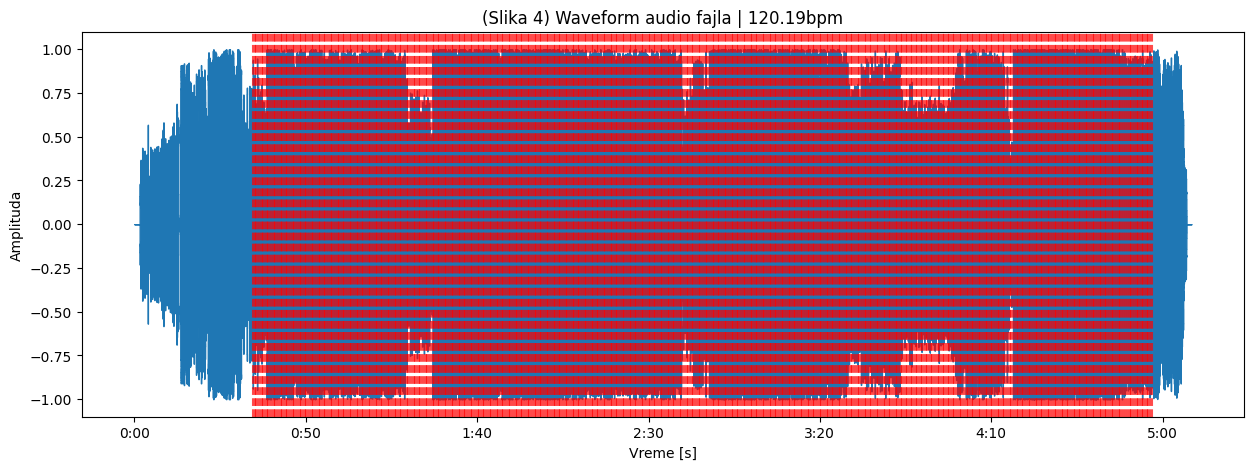

In [23]:
plt.figure(figsize=(15, 5))
librosa.display.waveshow(
    signal,
    sr=sr
)

for beat in beat_times:
    plt.axvline(
        x=beat,
        color='red',
        linestyle='--',
        alpha=0.7
    )

plt.title(f'(Slika 4) Waveform audio fajla | {round(float(tempo_drums), 2)}bpm')
plt.xlabel('Vreme [s]')
plt.ylabel('Amplituda')
plt.show()

# 6. Harmonijska analiza - Chroma obeležja

Da bi se pesmi mogao odrediti tonalitet (npr. „pesma je u tonalitetu C dura”), ili da bi se, kao u poglavlju 8, prepoznale konkretne note koje svira neki instrument, potrebno je iz signala izdvojiti informaciju o tome koje **muzičke note** su prisutne u datom trenutku, i kojim intenzitetom. Za tu svrhu koristi se **chroma** obeležje (*chroma feature*).

### 6.1. Šta je chroma i zašto je nezavisna od oktave

U muzičkoj teoriji, postoji ukupno 12 nota unutar jedne oktave: **C, C#, D, D#, E, F, F#, G, G#, A, A#, B** (U zapadnoj muzici oktava se deli na dvanaest polustepena, odnosno nota: C, C#, D, D#, E, F, F#, G, G#, A, A# i B, što predstavlja osnovu ravnomerno temperovanog tonskog sistema *(Krumhansl, 1990)*). Nota **C** u jednoj oktavi i nota **C** u sledećoj, višoj oktavi, zvuče muzički „srodno”, odnosno, imaju istu „klasu tona” (*pitch class*), iako im je fizička frekvencija različita (viša oktava iste note ima tačno **duplo** veću frekvenciju od niže). Chroma obeležje upravo iskorišćava ovu pravilnost: energiju signala na svim frekvencijama koje odgovaraju istoj noti, bez obzira na to u kojoj se oktavi nalaze, sabira u jednu zajedničku vrednost. Rezultat je, za svaki vremenski trenutak (frame), niz od tačno 12 brojeva, jedan za svaku od 12 nota, koji predstavlja koliko je energije prisutno za tu notu u tom trenutku, nezavisno od toga u kojoj oktavi je odsvirana.

Ovakva reprezentacija je izuzetno korisna za harmonijsku analizu (tonalitet, akordi) jer upravo *klasa tona*, a ne konkretna oktava, određuje harmonijski sadržaj (npr. da li je akord dur ili mol), pa chroma obeležje efikasno uklanja „nepotrebnu” informaciju o oktavi i fokusira analizu samo na muzički relevantan sadržaj.

### 6.2. Dve metode računanja chroma obeležja: `chroma_stft` i `chroma_cqt`

U radu se koriste dve različite metode za računanje chroma obeležja, koje se razlikuju po tome kako prvobitno analiziraju frekvencijski sadržaj signala:

- **`chroma_stft`** računa chroma obeležje na osnovu već poznate **STFT** transformacije (poglavlje 3), čije frekvencijske „kutije” (*bins*) su **linearno** raspoređene (svaka frekvencijska kutija pokriva jednak opseg Herca, bez obzira na to da li se nalazi u niskom ili visokom frekvencijskom području). Problem ove pristupa je što muzičke note nisu linearno, već **logaritamski** (eksponencijalno) raspoređene po frekvencijskoj osi (svaka sledeća oktava duplira frekvenciju), što znači da STFT sa linearnim kutijama ima znatno grublju frekvencijsku rezoluciju u niskom registru (gde su note bliže jedna drugoj u apsolutnim Hercima) nego u visokom, što može uticati na tačnost prepoznavanja nota, naročito basa.
- **`chroma_cqt`** se zasniva na **Constant-Q Transform (CQT)**, alternativi STFT-u čije frekvencijske kutije su, za razliku od STFT-a, raspoređene logaritamski, baš kao i muzičke note. Ovo znači da CQT ima konzistentnu, ravnomernu frekvencijsku rezoluciju **u muzičkom (logaritamskom) smislu** kroz čitav opseg, tačno prilagođenu strukturi muzičkih tonova, što je čini po pravilu preciznijom osnovom za chroma analizu, naročito u nižem frekvencijskom registru (kao što je bas) *(Brown,
1991)*.

U poglavlju 6 (opšta harmonijska analiza i detekcija tonaliteta) obračunavaju se i upoređuju rezultati dobijeni pomoću obe metode, dok se u poglavlju 8 (prikaz nota u realnom vremenu), gde je od ključne važnosti upravo preciznost u nižem registru, koristi isključivo `chroma_cqt`.

### 6.3. Priprema signala „ostalih” instrumenata

Pored analize cele pesme, u nastavku se harmonijska analiza sprovodi i nad izolovanom Demucs kategorijom `other` (svi instrumenti osim bubnjeva, basa i vokala, po pravilu gitare, klavijature i slično), jer se pretpostavlja da baš ti instrumenti najčešće nose glavni harmonijski (akordski) sadržaj pesme. Signal se, kao i u prethodnim poglavljima, svodi na mono i normalizuje.

In [24]:
instruments_signal = separated['other']
instruments_signal = np.mean(instruments_signal, axis=1)
instruments_signal = instruments_signal / np.max(np.abs(instruments_signal))

### 6.4. Računanje chroma obeležja

U ovoj ćeliji se chroma obeležje računa za tri različita signala (cela pesma, izolovani „ostali” instrumenti, HPSS harmonijska komponenta) i dvema metodama (`chroma_stft` i `chroma_cqt`) — ukupno šest kombinacija. Za `chroma_stft` se koriste isti parametri `n_fft` i `hop_length` definisani u poglavlju 3.1, radi konzistentnosti sa ranijom STFT analizom, dok `chroma_cqt` koristi svoje interne, podrazumevane parametre prilagođene CQT transformaciji.

In [25]:
chroma_song = librosa.feature.chroma_stft(
    y=signal,
    sr=sr,
    n_fft=n_fft,
    hop_length=hop_length
)
chroma_instruments = librosa.feature.chroma_stft(
    y=instruments_signal,
    sr=sr,
    n_fft=n_fft,
    hop_length=hop_length
)
chroma_harmonic_hpss = librosa.feature.chroma_stft(
    y=harmonic_signal,
    sr=sr,
    n_fft=n_fft,
    hop_length=hop_length
)


chroma_song_cqt = librosa.feature.chroma_cqt(
    y=signal,
    sr=sr
)
chroma_other_cqt = librosa.feature.chroma_cqt(
    y=instruments_signal,
    sr=sr
)
chroma_harmonic_cqt = librosa.feature.chroma_cqt(
    y=harmonic_signal,
    sr=sr
)

### 6.5. Vizuelizacija chroma obeležja

Funkcija `show_chroma_features` prikazuje chroma matricu kao dvodimenzionalnu „toplotnu mapu” (*heatmap*), pomoću `librosa.display.specshow`. Horizontalna osa je vreme, vertikalna osa je jedna od 12 nota, a boja svake tačke predstavlja intenzitet (energiju) te note u tom trenutku. Pošto `specshow` po podrazumevanim podešavanjima prikazuje note pod pretpostavkom da je prva nota `C` (tzv. „C major” konvencija numeracije), vertikalna osa se ovde eksplicitno postavlja (`plt.yticks`) na tačan redosled od 12 nota, počevši od C, kako bi oznake na grafiku bile ispravne i lako čitljive.

Ovakav prikaz omogućava da se vizuelno uoči koje note dominiraju u različitim delovima pesme, kao i da se uporedi koliko je chroma prikaz „čistiji” (jasnije definisane, uže lokalizovane trake energije oko određenih nota) kada se koristi izolovan instrument ili HPSS harmonijska komponenta u odnosu na celu, nerazdvojenu pesmu, u kojoj se energija svih instrumenata sabira zajedno *(Slika 5)*.

In [26]:
def show_chroma_features(chroma, title):
    plt.figure(figsize=(15, 6))

    librosa.display.specshow(
        chroma,
        x_axis='time',
        y_axis=None,
        hop_length=hop_length,
        cmap='coolwarm'
    )

    plt.yticks(
        np.arange(12),
        ['C', 'C#', 'D', 'D#', 'E', 'F',
         'F#', 'G', 'G#', 'A', 'A#', 'B']
    ) # na y-osi smo ovako predstavili note, zato što se bez toga prikazuju samo note u C maj

    plt.colorbar()
    plt.title(f'{title}')
    plt.xlabel('Vreme [s]')
    plt.ylabel('Nota')
    plt.show()

Slika 5


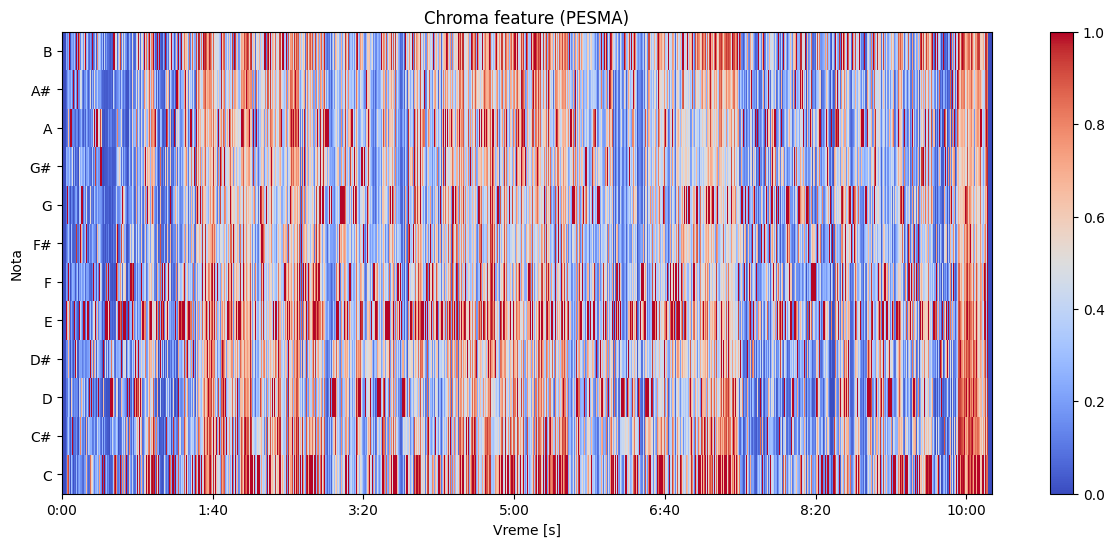

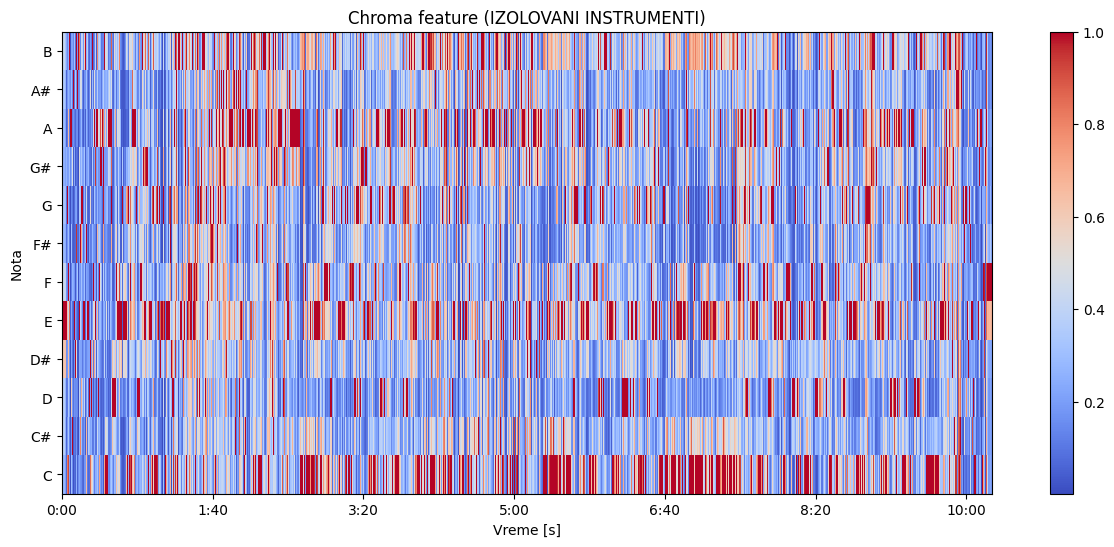

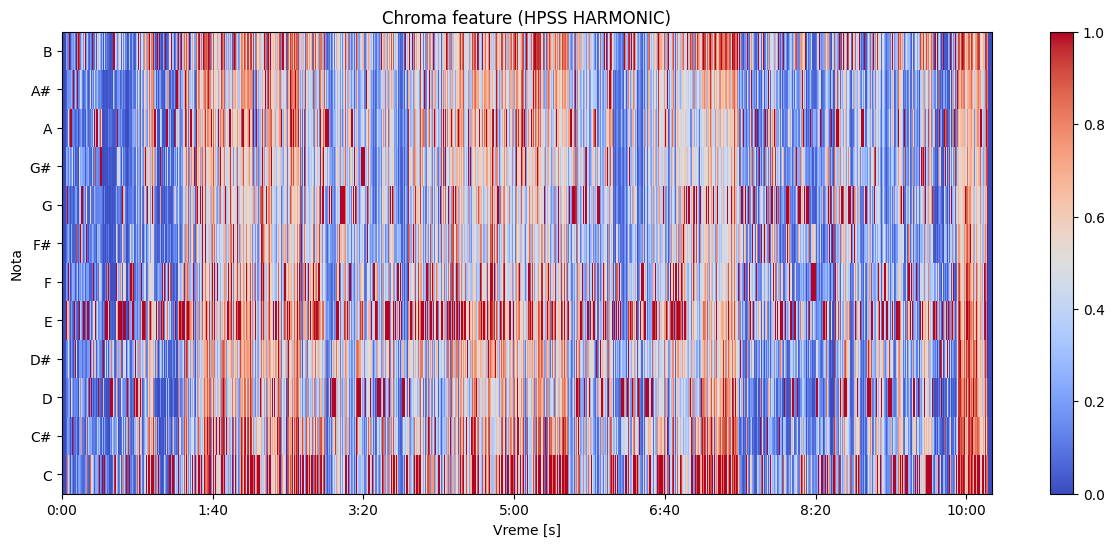

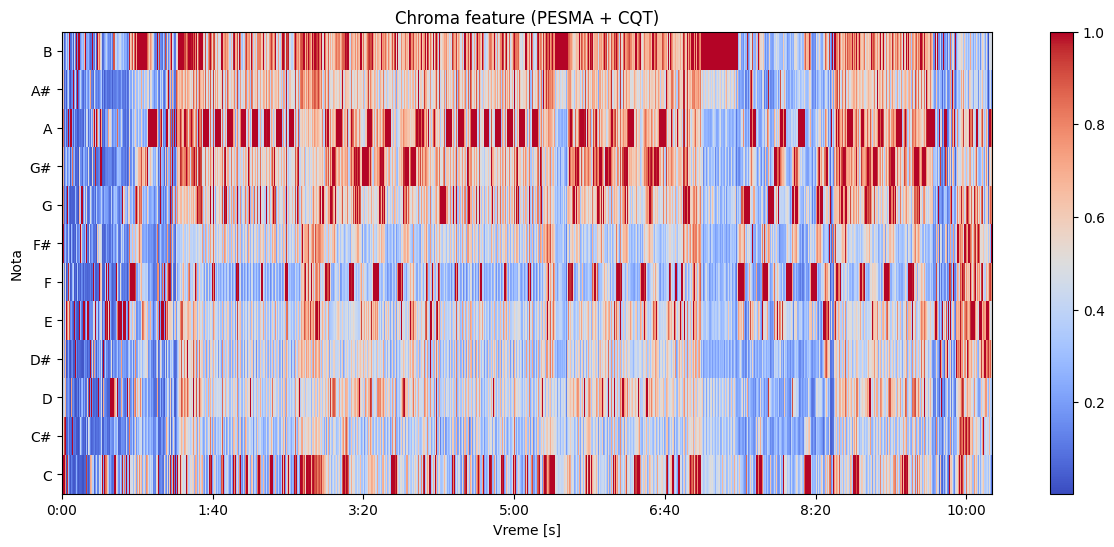

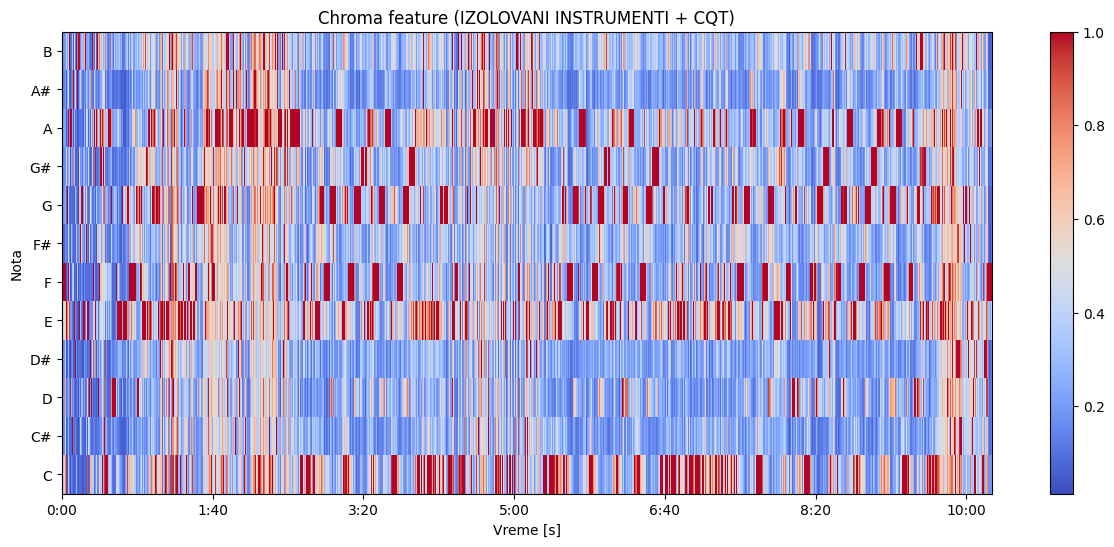

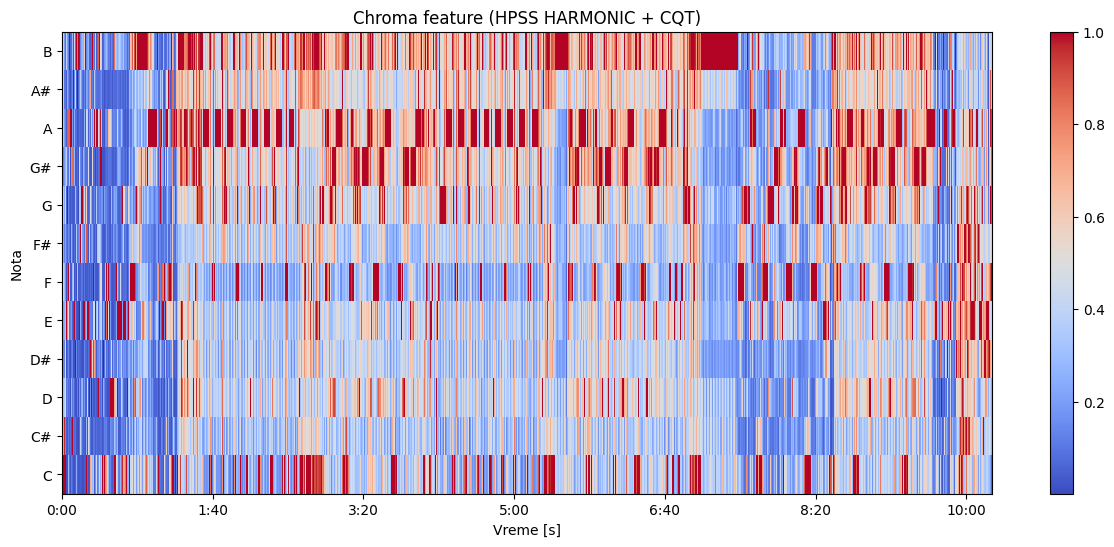

In [27]:
print("Slika 5")
show_chroma_features(chroma_song, 'Chroma feature (PESMA)')
show_chroma_features(chroma_instruments, 'Chroma feature (IZOLOVANI INSTRUMENTI)')
show_chroma_features(chroma_harmonic_hpss, 'Chroma feature (HPSS HARMONIC)')
show_chroma_features(chroma_song_cqt, 'Chroma feature (PESMA + CQT)')
show_chroma_features(chroma_other_cqt, 'Chroma feature (IZOLOVANI INSTRUMENTI + CQT)')
show_chroma_features(chroma_harmonic_cqt, 'Chroma feature (HPSS HARMONIC + CQT)')

### 6.6. Prosečna energija svake note

Da bi se harmonijski sadržaj pesme sažeo u jedan, lako uporediv oblik, chroma matrica (koja ima jednu vrednost po noti *za svaki* vremenski frame) se prosekuje kroz vreme (`np.mean(chroma, axis=1)`), čime se za svaku od 12 nota dobija jedna jedinstvena vrednost, koja predstavlja njenu **prosečnu energiju kroz celu pesmu**. Ova operacija je, kao što će biti pokazano u poglavlju 7, osnovni ulaz za algoritam detekcije tonaliteta, jer se tonalitet pesme po definiciji zasniva na tome koje note su u proseku najzastupljenije tokom cele pesme, a ne u pojedinačnom trenutku.

Lista `notes` ovde eksplicitno definiše redosled 12 nota (C, C#, D, ...) koji se koristi na svim mestima u radu gde je potrebno indeks note (0–11) prevesti u njeno čitljivo, tekstualno ime.

In [28]:
notes = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B']

chroma_song_mean = np.mean(chroma_song, axis=1)
chroma_instruments_mean = np.mean(chroma_instruments, axis=1)
chroma_harmonic_hpss_mean = np.mean(chroma_harmonic_hpss, axis=1)
chroma_song_cqt_mean = np.mean(chroma_song_cqt, axis=1)
chroma_other_cqt_mean = np.mean(chroma_other_cqt, axis=1)
chroma_harmonic_cqt_mean = np.mean(chroma_harmonic_cqt, axis=1)

Funkcija `show_average_notes_energy` prikazuje ovih 12 prosečnih vrednosti kao stubičasti dijagram (*bar chart*), sa numeričkom vrednošću ispisanom iznad svakog stuba radi lakšeg preciznog očitavanja. Poziv sledi za svih šest kombinacija signala/metode obračunatih u poglavlju 6.4 *(Slika 6)*.

In [29]:
def show_average_notes_energy(chroma, title):

    plt.figure(figsize=(12, 5))

    bars = plt.bar(notes, chroma)

    for bar in bars:
        height = bar.get_height()
        plt.text(
            x=bar.get_x() + bar.get_width() / 2,
            y=height,
            s=f'{height:.3f}',
            ha='center',
            va='bottom'
        )

    plt.title(title)
    plt.xlabel('Note')
    plt.ylabel('Energija')

    plt.show()

Slika 6


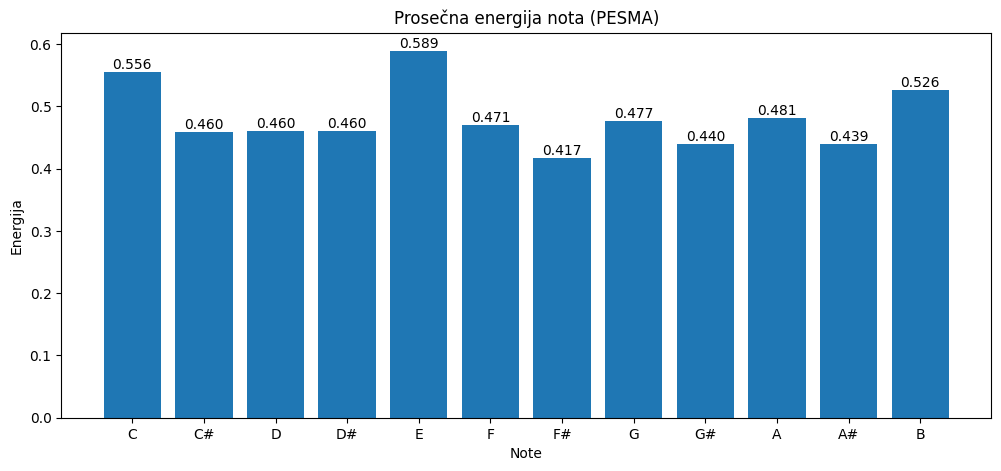

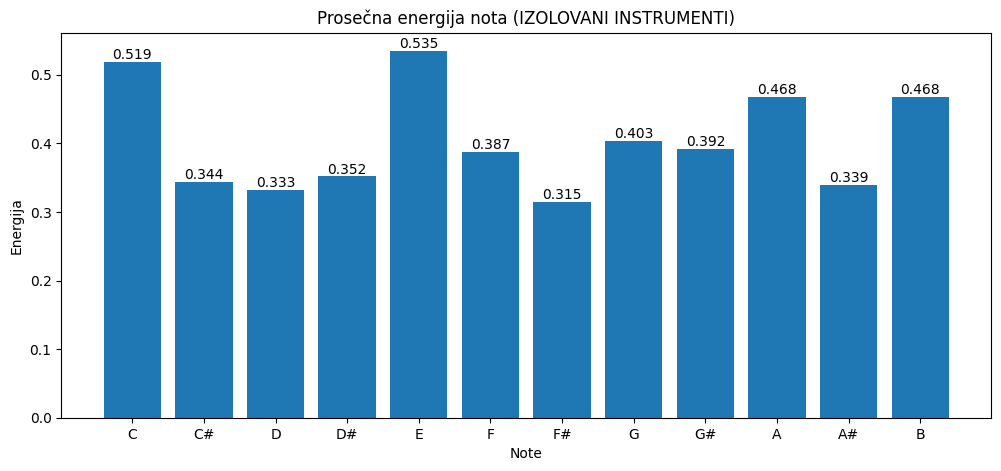

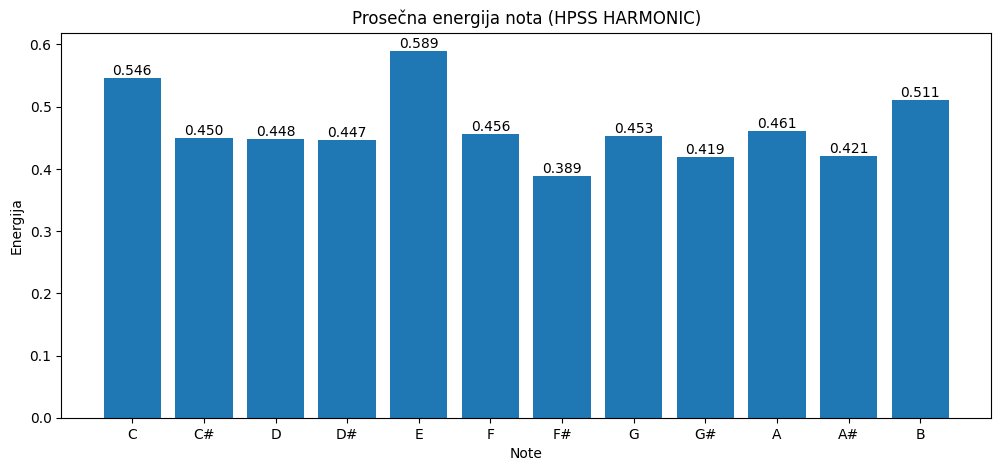

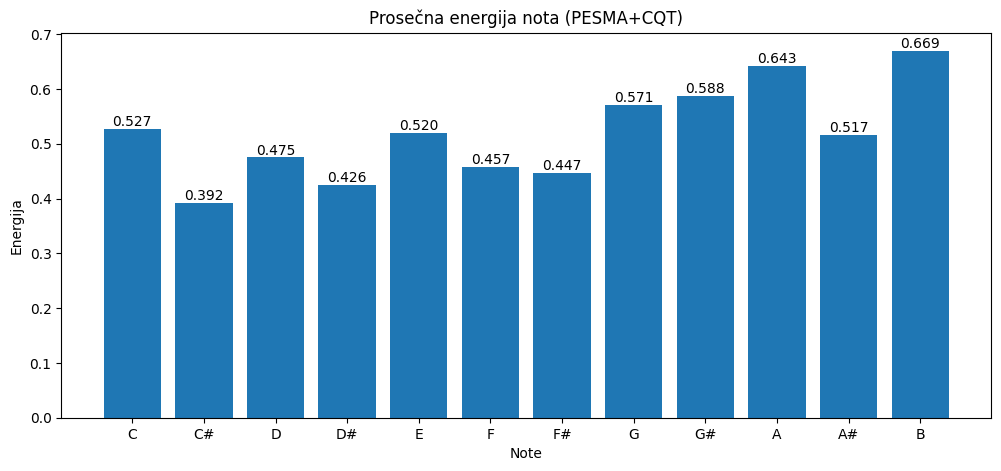

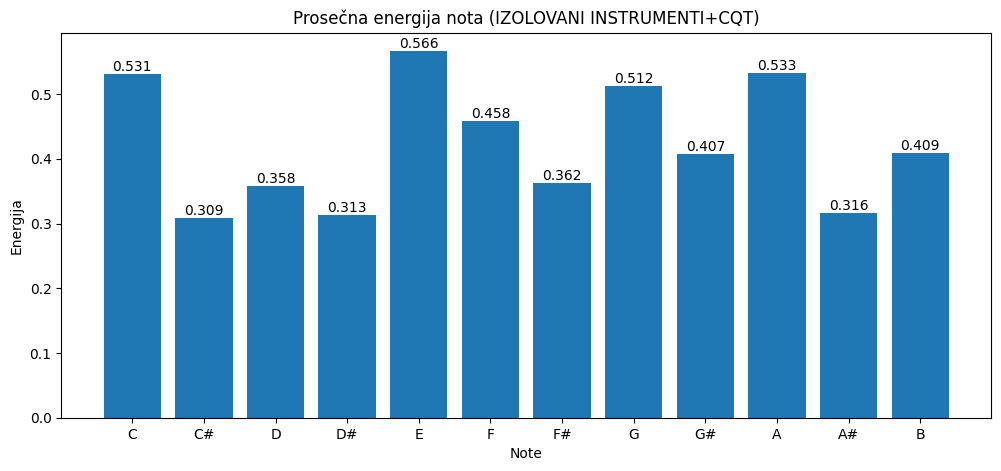

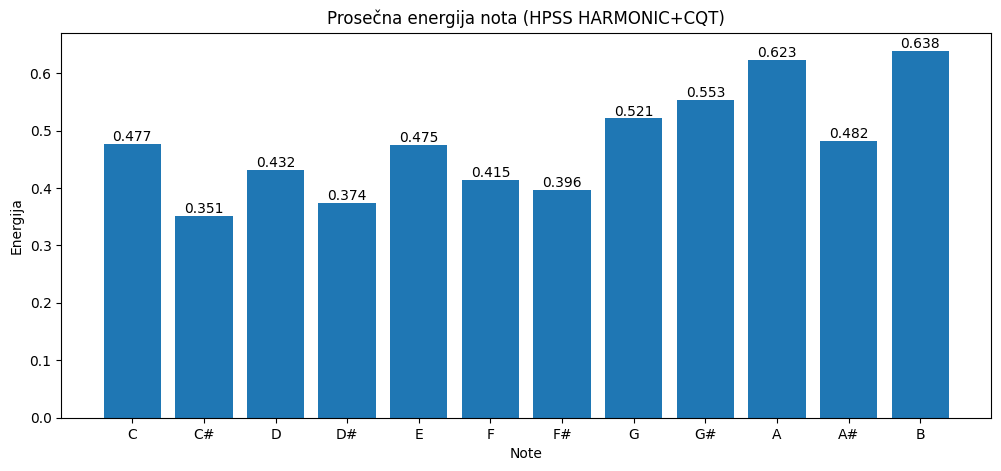

In [30]:
print("Slika 6")
show_average_notes_energy(chroma_song_mean, 'Prosečna energija nota (PESMA)')
show_average_notes_energy(chroma_instruments_mean, 'Prosečna energija nota (IZOLOVANI INSTRUMENTI)')
show_average_notes_energy(chroma_harmonic_hpss_mean, 'Prosečna energija nota (HPSS HARMONIC)')
show_average_notes_energy(chroma_song_cqt_mean, 'Prosečna energija nota (PESMA+CQT)')
show_average_notes_energy(chroma_other_cqt_mean, 'Prosečna energija nota (IZOLOVANI INSTRUMENTI+CQT)')
show_average_notes_energy(chroma_harmonic_cqt_mean, 'Prosečna energija nota (HPSS HARMONIC+CQT)')

Razlika između prosečnih energija noti je jasnija kod izolovanih instrumenata, što dovodi mnogo bržeg, jednostavnijeg i očiglednijeg određivanja tonaliteta.

# 7. Detekcija tonaliteta - Krumhansl-Schmuckler algoritam

**Tonalitet** (*musical key*) pesme opisuje oko koje note i kog tipa skale (**dur/major** ili **mol/minor**) je harmonijski organizovana čitava kompozicija, npr. „pesma je u tonalitetu A mol” znači da se većina akorda i melodijskih linija u pesmi grupiše oko note A i tonova mol skale izgrađene na njoj. Tonalitet je jedan od osnovnih muzičko-teorijskih deskriptora kompozicije, i njegovo automatsko prepoznavanje je klasičan problem u oblasti *Music Information Retrieval* (MIR).

### 7.1. Krumhansl-Schmuckler profili

**Krumhansl–Schmuckler (K-S) algoritam**, koji su psiholozi Carol Krumhansl i Mark Schmuckler predložili osamdesetih godina 20. veka, danas predstavlja jedan od najpoznatijih i najčešće korišćenih pristupa automatskoj detekciji tonaliteta. Algoritam se zasniva na **K-S profilima**, dva niza od po 12 brojeva (jedan za dur, jedan za mol tonalitet), koji predstavljaju empirijski utvrđenu „tipičnu važnost” (perceptualnu stabilnost) svake od 12 nota unutar datog tipa tonaliteta. Ove vrednosti nisu proizvoljno izabrane, već su originalno dobijene psihoakustičkim eksperimentima, u kojima su ispitanici procenjivali koliko dobro se određena nota „uklapa” nakon što im je odsviran jasan harmonijski kontekst određenog tonaliteta. Note koje čine osnovni akord tonalitieta (tonika, tercа, kvinta) dobijaju najviše vrednosti, dok note koje su harmonijski udaljenije od tog tonaliteta dobijaju niže vrednosti.

Osnovna ideja algoritma je: ako se prosečna energija nota pesme (izračunata u poglavlju 6.6) *podudara* sa K-S profilom određenog tonaliteta, veoma je verovatno da je pesma upravo u tom tonalitetu.

In [31]:
major_profile = np.array([
    6.35, 2.23, 3.48, 2.33,
    4.38, 4.09, 2.52, 5.19,
    2.39, 3.66, 2.29, 2.88
])

minor_profile = np.array([
    6.33, 2.68, 3.52, 5.38,
    2.60, 3.53, 2.54, 4.75,
    3.98, 2.69, 3.34, 3.17
])

### 7.2. Funkcija za detekciju tonaliteta

Funkcija `detect_key` prima prosečnu chroma energiju pesme (`chroma_mean`, niz od 12 vrednosti dobijen u poglavlju 6.6) i vraća procenjeni tonalitet. Postupak se sastoji od sledećih koraka:

1. **Rotacija profila.** Pošto su K-S profili definisani počevši od note C, a pesma teoretski može biti u bilo kom od 12 tonaliteta (C dur, C# dur, D dur, ...), profil se **rotira** (`np.roll`) za `i` mesta, za svako `i` od 0 do 11, čime se, u svakoj iteraciji, simulira da je profil „pomeren” tako da odgovara tonalitetu izgrađenom na i-toj noti (npr. rotacija za 2 mesta simulira profil D dur tonaliteta, jer je D druga nota iznad C). Ovaj postupak se ponavlja i za dur (`major_profile`) i za mol (`minor_profile`) profil.
2. **Računanje korelacije.** Za svaku od ovih 12 rotacija, računa se **Pearsonov koeficijent korelacije** (`np.corrcoef`) između stvarno izmerene prosečne chroma energije pesme i rotiranog K-S profila. Koeficijent korelacije je statistička mera koja kvantifikuje koliko dva niza brojeva „liče” jedan na drugi, u opsegu od $-1$ (potpuno suprotni obrasci) do $1$ (identičan obrazac); vrednost blizu $1$ znači da pesma i pretpostavljeni tonalitet imaju vrlo slične profile raspodele energije po notama *(Cohen, 1988)*.
3. **Izbor najboljeg poklapanja.** Od svih 24 izračunatih korelacija (12 rotacija × 2 tipa skale), bira se ona sa najvećom vrednošću (`np.argmax`). Nota i tip skale (dur/mol) koji ostvaruju najveću korelaciju proglašavaju se detektovanim tonalitetom pesme, a sama vrednost korelacije se vraća kao mera **pouzdanosti** (*confidence*) te detekcije, što je vrednost bliža 1, algoritam je „sigurniji” u svoju procenu.

In [32]:
def detect_key(chroma_mean):

    major_scores = []
    minor_scores = []

    for i in range(12):
        rotated_major = np.roll(major_profile, i)
        rotated_minor = np.roll(minor_profile, i)

        major_corr = np.corrcoef(
            chroma_mean,
            rotated_major
        )[0, 1]

        minor_corr = np.corrcoef(
            chroma_mean,
            rotated_minor
        )[0, 1]

        major_scores.append(major_corr)
        minor_scores.append(minor_corr)

    best_major = np.argmax(major_scores)
    best_minor = np.argmax(minor_scores)

    major_score = major_scores[best_major]
    minor_score = minor_scores[best_minor]

    if major_score > minor_score:
        detected_key = f"{notes[best_major]} Major"
        confidence = major_score
    else:
        detected_key = f"{notes[best_minor]} Minor"
        confidence = minor_score

    return detected_key, confidence, major_scores, minor_scores

### 7.3. Primena detekcije nad svim varijantama signala

Funkcija `detect_key` se ovde primenjuje nad svih šest prosečnih chroma nizova izračunatih u poglavlju 6.6, nad celom pesmom, izolovanim instrumentima i HPSS harmonijskom komponentom, svaki put pomoću oba metoda računanja chroma obeležja (`chroma_stft` i `chroma_cqt`). Cilj ovog poređenja je da se utvrdi da li predobrada signala (razdvajanje izvora, izbor metode chroma ekstrakcije) utiče na tačnost i pouzdanost detekcije tonaliteta, i ako utiče, u kojoj meri i u kom pravcu.

In [33]:
song_key, song_conf, song_major_scores, song_minor_scores = detect_key(chroma_song_mean)
demucs_key, demucs_conf, demucs_major_scores, demucs_minor_scores = detect_key(chroma_instruments_mean)
hpss_key, hpss_conf, hpss_major_scores, hpss_minor_scores = detect_key(chroma_harmonic_hpss_mean)
song_key_cqt, song_conf_cqt, song_major_scores_cqt, song_minor_scores_cqt = detect_key(chroma_song_cqt_mean)
demucs_key_cqt, demucs_conf_cqt, demucs_major_scores_cqt, demucs_minor_scores_cqt = detect_key(chroma_other_cqt_mean)
hpss_key_cqt, hpss_conf_cqt, hpss_major_scores_cqt, hpss_minor_scores_cqt = detect_key(chroma_harmonic_cqt_mean)

### 7.4. Vizuelizacija korelacija po tonalitetima

Funkcija `visualize_correlation_between_notes` crta dve linije preko 12 mogućih tonika, jednu za dur korelacije, jednu za mol korelacije,  dobijene u prethodnom koraku za dati signal. Ovakav grafik omogućava vizuelnu procenu **sigurnosti** detekcije. Ukoliko postoji jedan izrazit, oštar vrh koji je znatno veći od svih ostalih vrednosti, detekcija tonaliteta je pouzdana i jednoznačna. Ukoliko su, s druge strane, vrednosti više „izravnate” (nekoliko tonaliteta imaju sličnu, blisku korelaciju), to ukazuje na harmonijsku dvosmislenost pesme, situaciju u kojoj čak i iskusan muzičar ne bi mogao sa potpunom sigurnošću da odredi jedinstven tonalitet, jer pesma sadrži elemente više srodnih tonaliteta (npr. modulacije, ili blisku relaciju dur/mol tonaliteta koji dele iste note, kao C dur i A mol) *(Slika 7)*.

In [34]:
def visualize_correlation_between_notes(major_scores, minor_scores, title):
    plt.figure(figsize=(14, 5))

    plt.plot(notes, major_scores, label='Major')
    plt.plot(notes, minor_scores, label='Minor')

    plt.title(f'Korelacija tonaliteta | {title}')
    plt.xlabel('Tonalitet')
    plt.ylabel('Korelacija')

    plt.legend()
    plt.grid()

    plt.show()

Slika 7


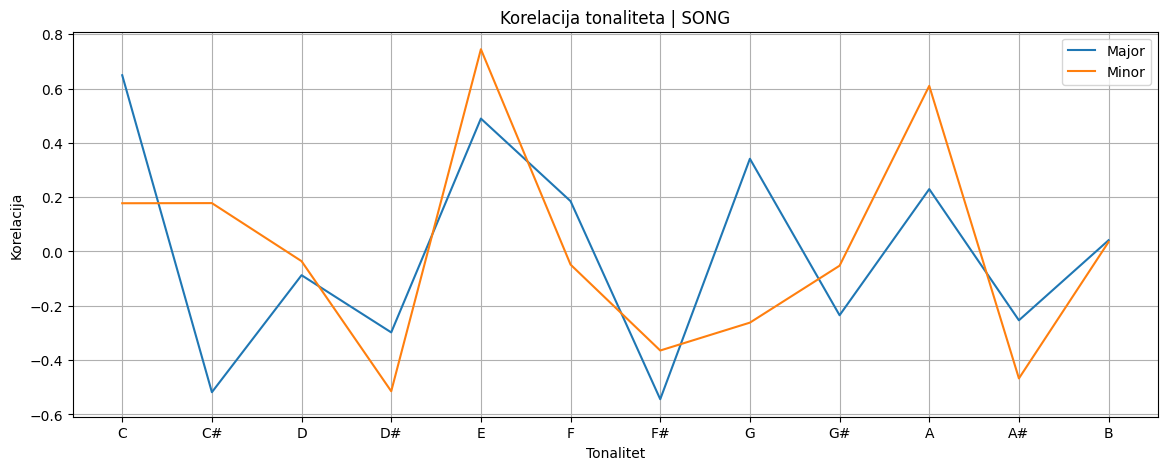

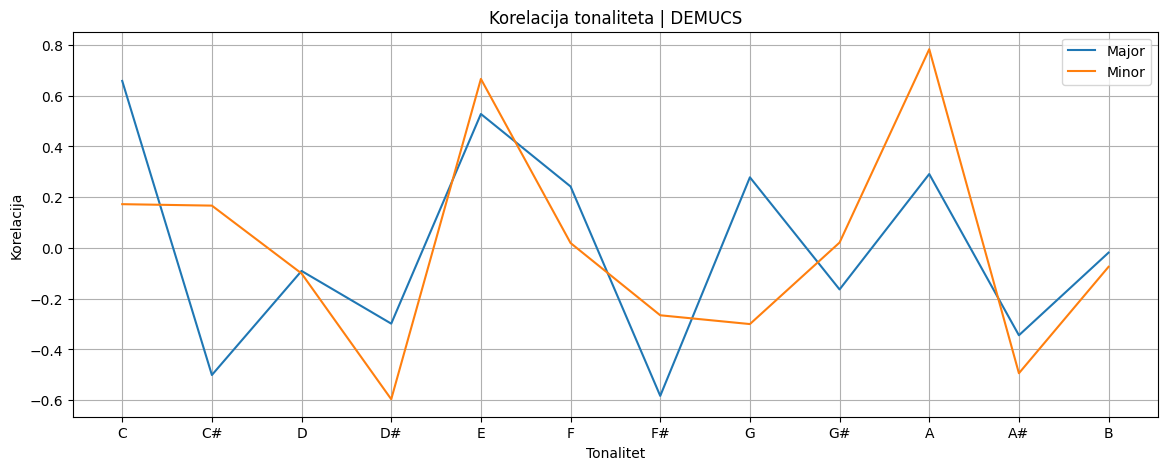

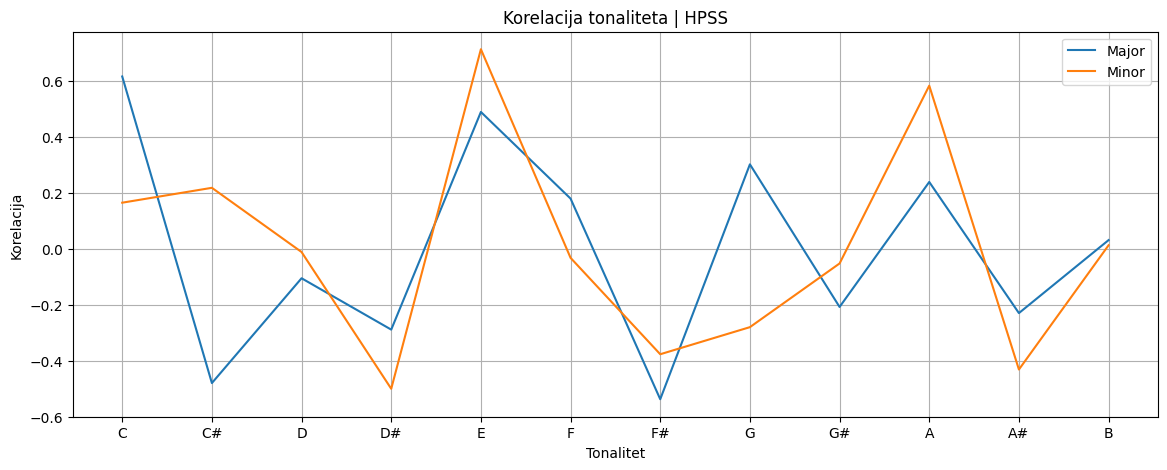

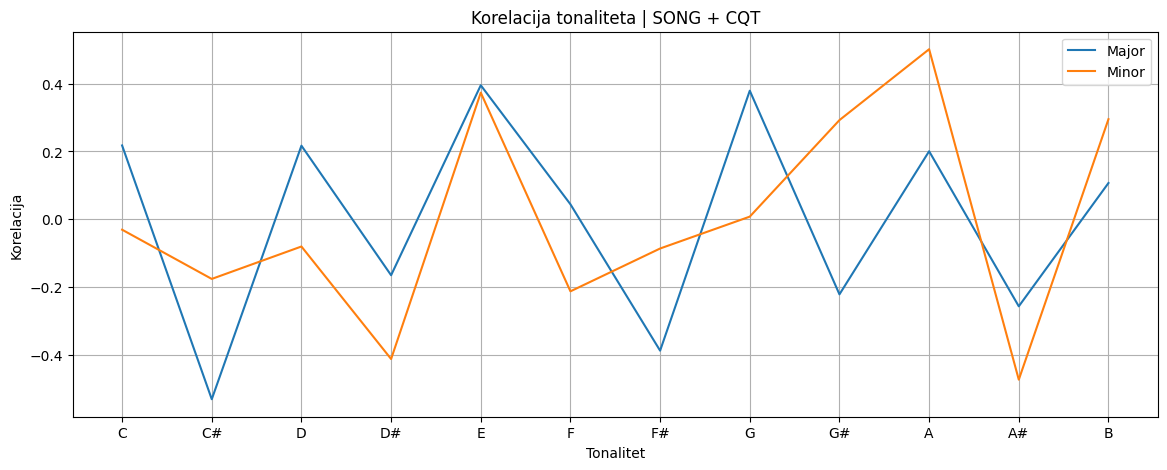

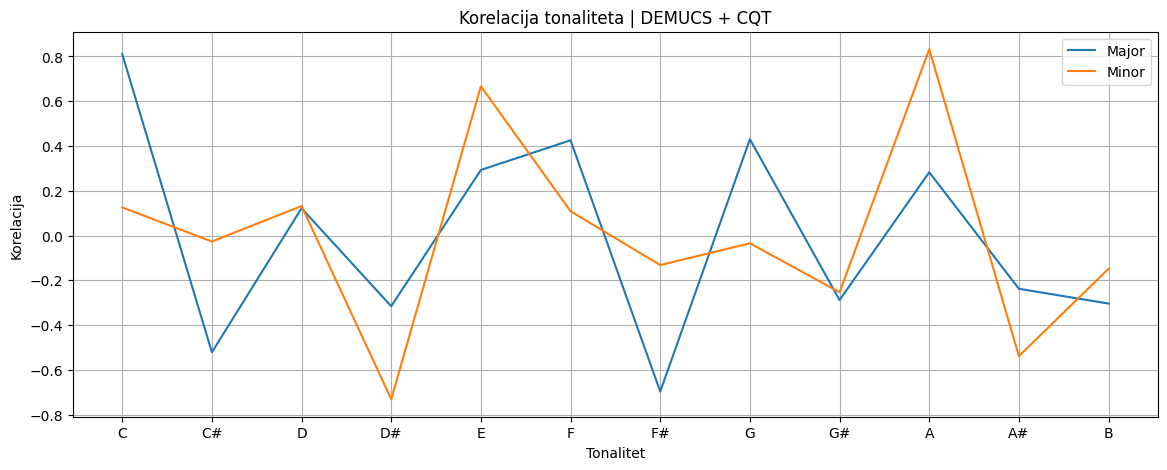

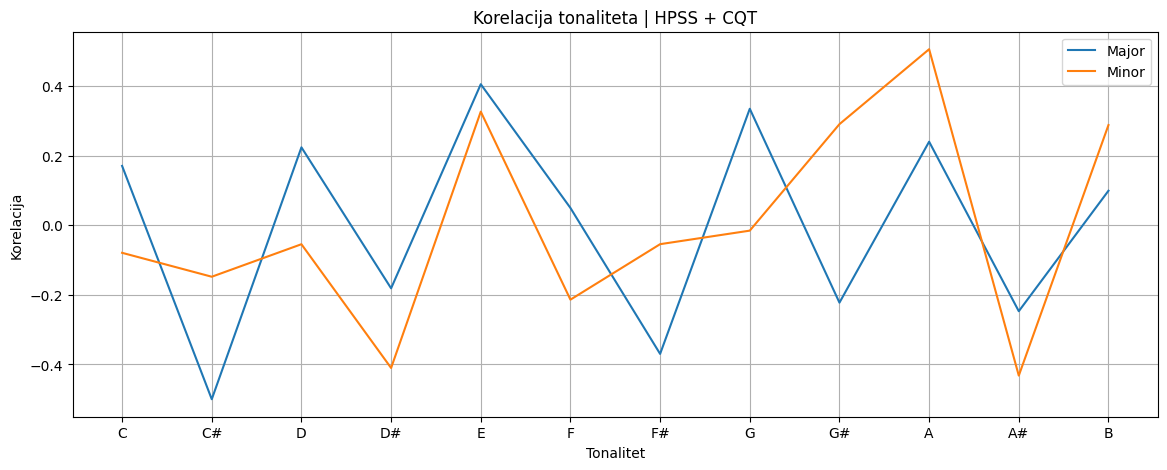

In [35]:
print("Slika 7")
visualize_correlation_between_notes(song_major_scores, song_minor_scores, 'SONG')
visualize_correlation_between_notes(demucs_major_scores, demucs_minor_scores, 'DEMUCS')
visualize_correlation_between_notes(hpss_major_scores, hpss_minor_scores, 'HPSS')
visualize_correlation_between_notes(song_major_scores_cqt, song_minor_scores_cqt, 'SONG + CQT')
visualize_correlation_between_notes(demucs_major_scores_cqt, demucs_minor_scores_cqt, 'DEMUCS + CQT')
visualize_correlation_between_notes(hpss_major_scores_cqt, hpss_minor_scores_cqt, 'HPSS + CQT')

### 7.5. Poređenje sa stvarnim (referentnim) tonalitetom

Radi objektivne evaluacije tačnosti svih prethodno opisanih pristupa, iz pomoćne datoteke `new_results.csv` učitava se **ručno (manuelno) utvrđen, referentan tonalitet** (`manual_key`) za obrađivanu pesmu, vrednost koju je unapred odredio čovek (na zvanično objavljenog notnog materijala), i koja se smatra „tačnim odgovorom” (*ground truth*) prema kome se ocenjuje tačnost automatske detekcije.

In [36]:
df = pd.read_csv('new_results.csv')
song_file_name = file_name + ".wav"
song_details = df[df['song_name'] == song_file_name]
correct_key = song_details['manual_key'].iloc[0]

U tabeli koja sledi se, radi lakog i sistematičnog poređenja, prikazuju se referentni (manuelno utvrđen) tonalitet, kao i svih šest automatski detektovanih tonaliteta (za svaku kombinaciju izvora signala i metode chroma ekstrakcije), zajedno sa odgovarajućom vrednošću pouzdanosti (korelacije) svake detekcije.

In [37]:
data = {
    'Detected on:': ['Correct key', 'Song', 'Isolated instruments (Demucs)', 'HPSS Harmonic', 'Song + CQT', 'Isolated instruments (Demucs) + CQT', 'HPSS Harmonic + CQT'],
    'Detected key:': [correct_key, song_key, demucs_key, hpss_key, song_key_cqt, demucs_key_cqt, hpss_key_cqt],
    'Confidence:': [1, song_conf, demucs_conf, hpss_conf, song_conf_cqt, demucs_conf_cqt, hpss_conf_cqt]
}
key_df = pd.DataFrame(data)
key_df

,Detected on:,Detected key:,Confidence:
0,Correct key,A Minor,1.000000
1,Song,E Minor,0.744774
2,Isolated instruments (Demucs),A Minor,0.783232
3,HPSS Harmonic,E Minor,0.711857
4,Song + CQT,A Minor,0.501149
5,Isolated instruments (Demucs) + CQT,A Minor,0.832172
6,HPSS Harmonic + CQT,A Minor,0.505357


# 8. Prikaz nota izolovanih instrumenata u realnom vremenu

Poslednji deo rada demonstrira praktičnu primenu prethodno objašnjenih koncepata (chroma obeležja, RMS energija) u interaktivnom scenariju. Dok se u pozadini reprodukuje izolovan instrument (bas ili vokal), korisniku se u realnom vremenu, sinhronizovano sa reprodukcijom, prikazuje koju konkretnu notu treba u tom trenutku da odsvira/otpeva, kao i koja je sledeća nota u nizu. Ovakav alat ima direktnu praktičnu vrednost za muzičare koji uče bassline ili melodijsku liniju pesme po sluhu, bez pristupa notnom zapisu.

### 8.1. Opšti princip

Za razliku od poglavlja 6 i 7, gde se chroma obeležje računalo kao **jedna prosečna vrednost kroz celu pesmu** (radi determinisanja tonaliteta), u ovom poglavlju je od interesa **dominantna nota u svakom pojedinačnom (kratkom) vremenskom trenutku**, jer je cilj pratiti kako se odsvirana nota menja kroz vreme, a ne odrediti jedinstven, sažet harmonijski opis cele pesme.

Postupak se sastoji od pet koraka, koji se identično primenjuju i na bas i na vokale:

1. Izolovan signal instrumenta se svodi na mono i normalizuje (isto kao u prethodnim poglavljima).
2. Računa se **chroma** obeležje (metodom `chroma_cqt`, iz razloga objašnjenih u poglavlju 6.2 - bolja frekvencijska rezolucija u niskom registru, relevantna posebno za bas) i **RMS energija** (mera trenutne glasnoće signala), po istom rasporedu vremenskih frame-ova.
3. Za svaki frame se određuje **dominantna nota** (nota sa najvećom chroma vrednošću), ali **samo ukoliko** je RMS energija u tom frame-u iznad zadatog praga; u suprotnom se frame označava kao „tišina/šum”, čime se sprečava da algoritam „izmišlja” lažne note u delovima signala gde instrument u stvarnosti ne svira (npr. usled artefakata nastalih tokom Demucs separacije, koja retko postiže potpunu, savršenu tišinu na mestima gde instrument stvarno ne svira).
4. Uzastopni frame-ovi sa istom notom se grupišu u **note-segmente** (koji imaju početak, kraj i identitet note), segmenti kraći od zadatog minimalnog trajanja se odbacuju kao šum, a preostali susedni segmenti sa istom notom se spajaju u jedan.
5. Instrument se pušta u pozadini, a paralelno se, u tačnoj sinhronizaciji sa protokom vremena reprodukcije, ispisuje trenutna i sledeća nota.

## 8.2. Bass

### 8.2.1. Priprema biblioteka za reprodukciju zvuka

Za reprodukciju audio signala direktno iz Jupyter notebook-a (za razliku od prethodnih poglavlja, gde se zvuk samo analizirao, ali nikada zvučno reprodukovao) potrebna je nova biblioteka, `sounddevice`, koja omogućava puštanje numpy niza kao zvuka kroz audio izlaz (zvučnike/slušalice) računara. Funkcija `clear_output` iz `IPython.display` biće korišćena u nastavku za ažuriranje teksta koji se ispisuje na ekranu (brisanje starog i ispis novog teksta), radi simulacije efekta „živog”, ažurirajućeg prikaza.

In [38]:
import sounddevice as sd
from IPython.display import clear_output

### 8.2.2. Priprema izolovanog bas signala

Izolovan bas signal (`separated['bass']`, dobijen Demucs separacijom u poglavlju 4.1) se, na isti način kao i u svim prethodnim poglavljima, svodi na mono kanal (prosekom levog i desnog kanala) i normalizuje na opseg $[-1, 1]$, čime se dobija konzistentan ulaz za sve naredne korake.

In [39]:
bass_signal = separated['bass']
bass_mono = np.mean(bass_signal, axis=1)
bass_mono = bass_mono / np.max(np.abs(bass_mono))

### 8.2.3. Chroma obeležje, RMS energija i dominantna nota po frame-u

Ova ćelija predstavlja tehničko srce cele metode prikaza nota u realnom vremenu, i sastoji se od nekoliko koraka:

1. **`chroma_bass = librosa.feature.chroma_cqt(...)`** - računa se chroma obeležje bas signala, metodom `chroma_cqt` (objašnjenom u poglavlju 6.2), sa istim parametrom `hop_length_bass=512` kao u ostatku rada, radi vremenske preciznosti dovoljne za praćenje relativno brzih promena note.

2. **`rms_bass = librosa.feature.rms(...)`** - **RMS** (*Root Mean Square*) je standardna statistička mera koja, primenjena nad zvučnim signalom, kvantifikuje njegovu prosečnu **energiju**, odnosno **glasnoću**, u datom kratkom vremenskom okviru (`frame_length_bass=2048` uzoraka). Fizički, veća RMS vrednost znači da su amplitude signala u tom okviru u proseku veće, što odgovara glasnijem zvuku. Ova vrednost se računa nezavisno od chroma obeležja i služi isključivo kao pokazatelj *da li* instrument u datom trenutku uopšte proizvodi zvuk, bez obzira na to *koju* notu.

3. **`rms_db = librosa.amplitude_to_db(rms_bass, ref=np.max)`** - RMS vrednosti se, iz istog razloga kao i kod spektrograma u poglavlju 3.3 (bolje podudaranje sa ljudskom perceptcijom glasnoće, sažimanje širokog opsega vrednosti), konvertuju u decibelnu skalu, relativno u odnosu na najglasniji trenutak u signalu (kome se dodeljuje vrednost 0 dB).

4. **`is_active = rms_db > silence_threshold_db`** - definiše se prag od `-40` dB; svaki frame čija je glasnoća **manja** od 40 dB ispod najglasnijeg dela signala smatra se **tišinom ili šumom** (npr. artefakt nastao usled nesavršenosti Demucs separacije, gde se u pauzama basa mogu javiti tihi „ostaci” drugih instrumenata), i tretira se posebno u narednom koraku.

5. **`dominant_note_indices = np.argmax(chroma_bass, axis=0)`** - za svaki frame se, nezavisno od RMS energije, prvo pronalazi **dominantna nota**, nota sa najvećom chroma vrednošću (najvećom energijom) u tom frame-u, pomoću funkcije `np.argmax` koja vraća indeks (0–11) najveće vrednosti u nizu.

6. **`dominant_note_indices = np.where(is_active, dominant_note_indices, -1)`** - konačno, dominantna nota se **poništava** (zamenjuje specijalnom vrednošću `-1`, koja simbolički predstavlja „nema note”) za sve frame-ove koji su u koraku 4 označeni kao tišina/šum. Ovim se sprečava da algoritam u potpunosti tihim delovima signala „nasumično” bira neku notu isključivo na osnovu (u tom trenutku irelevantnog, šumovitog) chroma obeležja.

7. **`frame_times = librosa.frames_to_time(...)`** - na kraju se, kao i u poglavlju 5.4, indeksi frame-ova konvertuju u stvarno vreme (u sekundama), radi kasnijeg tačnog sinhronizovanja sa reprodukcijom audio signala.

In [40]:
hop_length_bass = 512
frame_length_bass = 2048

chroma_bass = librosa.feature.chroma_cqt(
    y=bass_mono,
    sr=sr,
    hop_length=hop_length_bass
)

rms_bass = librosa.feature.rms(
    y=bass_mono,
    frame_length=frame_length_bass,
    hop_length=hop_length_bass
)[0]

rms_db = librosa.amplitude_to_db(rms_bass, ref=np.max)

silence_threshold_db = -40

is_active = rms_db > silence_threshold_db

dominant_note_indices = np.argmax(chroma_bass, axis=0)
dominant_note_indices = np.where(is_active, dominant_note_indices, -1)

frame_times = librosa.frames_to_time(
    np.arange(chroma_bass.shape[1]),
    sr=sr,
    hop_length=hop_length_bass
)

### 8.2.4. Grupisanje frame-ova u note-segmente

Rezultat prethodne ćelije (`dominant_note_indices`) je niz u kome je za **svaki pojedinačni, veoma kratak frame** (dugačak samo `hop_length_bass / sr` ≈ 11.6 milisekundi) zapisana dominantna nota. Ovakva rezolucija je nepotrebno fina za prikaz korisniku. U stvarnosti, jedna odsvirana nota po pravilu traje znatno duže od 11.6 ms i prostire se kroz mnogo uzastopnih frame-ova.

Funkcija `build_note_segments` prolazi kroz niz `dominant_indices` frame po frame, i **grupiše uzastopne frame-ove sa istom notom** u jedan **segment**. Python rečnik sa tri ključa: `note` (indeks note), `start` i `end` (vreme početka i kraja segmenta, u sekundama). Svaki put kada se nota u nizu promeni u odnosu na prethodni frame, trenutni segment se „zatvara” (dodaje u listu `segments`) i započinje novi. Poslednji segment se zatvara posebno, nakon završetka petlje, uz aproksimaciju njegovog kraja na osnovu trajanja poslednjeg frame-a. Rezultat je znatno kompaktnija i muzički smislenija reprezentacija, tačnije, lista segmenata, od kojih svaki predstavlja jednu neprekidnu „notu” (ili tišinu, kodiranu kao `-1`) određenog trajanja.

In [41]:
def build_note_segments(dominant_indices, frame_times):
    segments = []

    current_note = dominant_indices[0]
    segment_start = frame_times[0]

    for i in range(1, len(dominant_indices)):
        if dominant_indices[i] != current_note:
            segments.append({
                'note': current_note,
                'start': segment_start,
                'end': frame_times[i]
            })
            current_note = dominant_indices[i]
            segment_start = frame_times[i]

    frame_duration = frame_times[-1] - frame_times[-2] if len(frame_times) > 1 else 0.0
    segments.append({
        'note': current_note,
        'start': segment_start,
        'end': frame_times[-1] + frame_duration
    })

    return segments


note_segments = build_note_segments(dominant_note_indices, frame_times)

### 8.2.5. Odbacivanje tišine, filtriranje kratkih nota i spajanje segmenata

I nakon grupisanja u segmente, rezultat i dalje sadrži nepoželjne artefakte, koji se u ovoj ćeliji uklanjaju u tri uzastopna koraka:

1. **Uklanjanje segmenata tišine/šuma** (`active_segments`) - svi segmenti čija je nota jednaka `-1` (određeni kao tišina u koraku RMS filtriranja, poglavlje 8.2.3) se u potpunosti izbacuju iz razmatranja, bez obzira na njihovo trajanje.

2. **Filtriranje veoma kratkih segmenata** (`filtered_segments`) - preostaju samo segmenti čije trajanje (`end - start`) iznosi **najmanje** `min_note_duration = 0.15` sekundi. Ovaj korak je neophodan jer, i pored RMS filtriranja, chroma analiza može trenutno, u pojedinačnim frame-ovima, pogrešno detektovati kratkotrajan „blic” pogrešne note usled prelaznih akustičkih efekata (npr. harmonici, ili artefakti same Demucs separacije). Takvi izuzetno kratki segmenti (kraći od 150 milisekundi, što je ispod granice trajanja koju ljudsko uho po pravilu percipira kao jasno odsviranu, nezavisnu notu) se stoga tretiraju kao šum i odbacuju.

3. **Spajanje susednih segmenata sa istom notom** (`merged_segments`) - nakon uklanjanja kratkih „šumnih” segmenata iz koraka 2, može se desiti da su dva segmenta sa **istom** notom, koji su ranije bili razdvojeni upravo tim (sada uklonjenim) kratkim šumnim segmentom, postali susedni. Ovakvi segmenti se spajaju u jedan, čime se izbegava nepotreban, veštački „trepćuć” prikaz iste note dva puta zaredom bez stvarne muzičke promene.

Na kraju ćelije se ispisuje broj segmenata u svakoj od faza obrade, broj sirovih segmenata (pre bilo kakvog filtriranja), broj segmenata nakon uklanjanja tišine, i broj konačnih segmenata nakon filtriranja i spajanja, što služi kao brz, kvantitativan pokazatelj koliko je „šuma” svaki korak filtriranja uspeo da ukloni.

In [42]:
min_note_duration = 0.15  # sekunde - note krace od ovoga se tretiraju kao sum i odbacuju

active_segments = [segment for segment in note_segments if segment['note'] != -1]

filtered_segments = [
    segment for segment in active_segments
    if (segment['end'] - segment['start']) >= min_note_duration
]

merged_segments = []

for segment in filtered_segments:
    if merged_segments and merged_segments[-1]['note'] == segment['note']:
        merged_segments[-1]['end'] = segment['end']
    else:
        merged_segments.append(dict(segment))

print(f'Broj sirovih segmenata: {len(note_segments)}')
print(f'Broj segmenata nakon uklanjanja tisine/suma: {len(active_segments)}')
print(f'Broj segmenata nakon filtriranja kratkih nota i spajanja: {len(merged_segments)}')


Broj sirovih segmenata: 553
Broj segmenata nakon uklanjanja tisine/suma: 455
Broj segmenata nakon filtriranja kratkih nota i spajanja: 281


### 8.2.6. Vizuelizacija nota kroz vreme

Funkcija `show_notes_timeline` crta konačnu listu note-segmenata u obliku horizontalnih linija (`plt.hlines`), vertikalna pozicija linije odgovara noti (od C do B), horizontalna dužina linije odgovara vremenskom trajanju te note (od `start` do `end`), a parametar `max_seconds` ograničava prikaz na uvid u prvi (podrazumevano jedan) minut pesme, radi čitljivosti grafika (prikaz cele, po pravilu nekoliko minuta duge pesme na jednom grafiku bio bi vizuelno nepregledan). Ovakav prikaz *(Slika 8)* predstavlja, u suštini, jednostavan, vizuelan „notni zapis” izdvojene linije basa kroz vreme, i omogućava brz uvid u strukturu i ponavljanje bassline melodije, bez potrebe da se pesma zaista i preslušava.

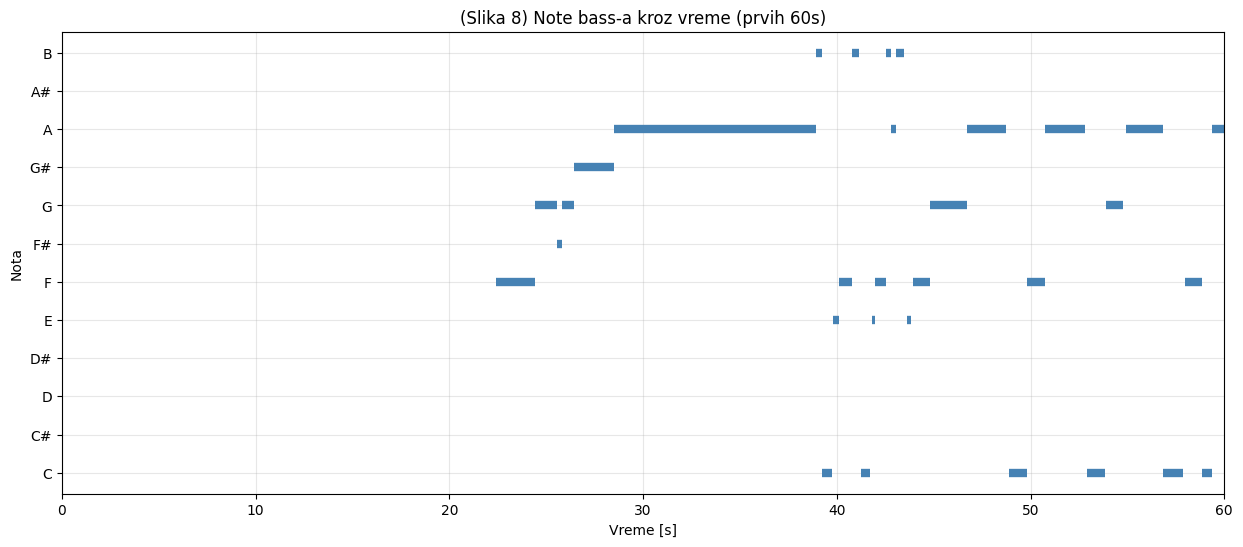

In [43]:
def show_notes_timeline(segments, note_names, max_seconds=60, title=None):
    plt.figure(figsize=(15, 6))

    for segment in segments:
        start = segment['start']
        end = segment['end']

        if start >= max_seconds:
            break

        end = min(end, max_seconds)
        note_index = segment['note']

        plt.hlines(
            y=note_index,
            xmin=start,
            xmax=end,
            linewidth=6,
            color='steelblue'
        )

    plt.yticks(np.arange(12), note_names)
    plt.xlim(0, max_seconds)
    plt.xlabel('Vreme [s]')
    plt.ylabel('Nota')
    if title is None:
        title = f'(Slika 8) Note bass-a kroz vreme (prvih {max_seconds}s)'
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.show()


show_notes_timeline(merged_segments, notes, max_seconds=60)

### 8.2.7. Reprodukcija bass-a uz sinhronizovan prikaz trenutne i sledeće note

Funkcija `play_bass_with_notes` predstavlja završni, interaktivni deo ove metode, i sastoji se od sledećih koncepcijskih delova:

- **Nezavisan `Output` widget** (`ipywidgets.Output`) se koristi kao stabilan, poseban prostor za tekstualni ispis. Ovo je neophodno jer standardni `print()` u kombinaciji sa globalnim `IPython.display.clear_output` pozivom, izvršavanim u brzoj, vremenski osetljivoj petlji, nije pouzdan. Front-end okruženje Jupyter-a ne stiže uvek da renderuje tekst pre nego što se izda naredba za brisanje sledećeg, što dovodi do toga da korisnik vidi „prazan” ili nepotpun ispis. `ipywidgets.Output` obezbeđuje sopstveni, izolovan i pouzdaniji mehanizam za takva česta ažuriranja.

- **Pokretanje reprodukcije zvuka** (`sd.play(bass_audio, sample_rate)`) je **neblokirajuće**, poziv se odmah vraća (ne čeka da se zvuk odsvira do kraja), a sama reprodukcija se odvija u posebnoj, nezavisnoj programskoj niti (thread), potpuno paralelno sa ostatkom Python koda. Ovo je upravo mehanizam koji omogućava da zvuk svira „u pozadini” dok se istovremeno u glavnoj petlji ispisuju note.

- **Glavna petlja** (`while True`) neprekidno, u kratkim, fiksnim intervalima (`poll_interval=0.05` sekundi), provera koliko je vremena (`elapsed`) proteklo od početka reprodukcije (`time.time() - playback_start`), i na osnovu toga utvrđuje **koji segment note** trenutno „treba” da bude aktivan pretragom kroz listu segmenata unapred od trenutno poznate pozicije (`current_index`). Ispis na ekranu (trenutna i sledeća nota) se ažurira **isključivo kada dođe do stvarne promene** aktivnog segmenta, a ne u svakoj iteraciji petlje, čime se izbegava suvišno, isprekidano „trepćuće” ažuriranje istog teksta.

- **Prekid reprodukcije** (`except KeyboardInterrupt`) - ukoliko korisnik prekine izvršavanje ćelije (npr. pritiskom na dugme za prekid u Jupyter-u), petlja hvata taj signal i **eksplicitno** zaustavlja audio reprodukciju pozivom `sd.stop()`. Ovaj korak je neophodan zato što se zvuk reprodukuje u nezavisnoj programskoj niti, koja **nije** automatski prekinuta samim prekidom Python interpretera. Bez eksplicitnog `sd.stop()` poziva, zvuk bi nastavio da se čuje i nakon prekida izvršavanja Python koda.

Ovom funkcijom se zatvara ceo tok obrade: od sirovog audio signala izolovanog basa, preko izdvajanja pojedinačnih nota, do njihovog interaktivnog, u realnom vremenu sinhronizovanog prikaza korisniku.

In [44]:
import sys
import ipywidgets as widgets
from IPython.display import display

def play_bass_with_notes(bass_audio, sample_rate, segments, note_names, poll_interval=0.05, label='bas-a'):
    if not segments:
        print('Nema detektovanih nota za prikaz.')
        return

    note_output = widgets.Output()
    display(note_output)

    with note_output:
        print(f'Pokrećem reprodukciju {label}...')

    sd.play(bass_audio, sample_rate)
    playback_start = time.time()

    total_duration = len(bass_audio) / sample_rate
    current_index = -1

    try:
        while True:
            elapsed = time.time() - playback_start

            if elapsed >= total_duration:
                break

            new_index = current_index
            for i in range(current_index + 1, len(segments)):
                if segments[i]['start'] <= elapsed:
                    new_index = i
                else:
                    break

            if new_index != current_index:
                current_index = new_index
                current_note = note_names[segments[current_index]['note']]
                next_note = (
                    note_names[segments[current_index + 1]['note']]
                    if current_index + 1 < len(segments) else '-'
                )

                with note_output:
                    note_output.clear_output(wait=True)
                    print(f'Trenutna nota: {current_note}    Sledeća nota: {next_note}')

            time.sleep(poll_interval)

        sd.wait()
        with note_output:
            note_output.clear_output(wait=True)
            print('Kraj pesme.')

    except KeyboardInterrupt:
        sd.stop()
        with note_output:
            note_output.clear_output(wait=True)
            print('Reprodukcija prekinuta od strane korisnika.')


play_bass_with_notes(bass_mono, sr, merged_segments, notes)

Output()

## 8.3. Vokali

Identičan postupak koji je detaljno objašnjen u poglavlju 8.2 za bas, ovde se primenjuje i na izolovan signal vokala (`separated['vocals']`). Pošto su svi koraci obrade (chroma ekstrakcija, RMS filtriranje, grupisanje u segmente, vizuelizacija, reprodukcija) potpuno opšti, ne zavise od toga koji je konkretno instrument u pitanju. U kodu se, umesto ponovnog pisanja identičnih funkcija, **ponovo koriste** već definisane funkcije `build_note_segments`, `show_notes_timeline` i `play_bass_with_notes` iz poglavlja 8.2, čime se izbegava nepotrebno dupliranje koda. Jedina razlika je u konkretnim ulaznim podacima (signal vokala umesto basa) i u nazivima promenljivih (sufiks `_vocals`, radi izbegavanja preklapanja sa promenljivama basa).

### 8.3.1. Priprema izolovanih vokala

In [45]:
vocals_signal = separated['vocals']
vocals_mono = np.mean(vocals_signal, axis=1)
vocals_mono = vocals_mono / np.max(np.abs(vocals_mono))

### 8.3.2. Chroma obeležje, RMS energija i dominantna nota po frame-u - vokali

Postupak je identičan onom iz poglavlja 8.2.3, primenjen nad signalom vokala umesto basa. Vredi napomenuti da je izbor praga `silence_threshold_db_vocals = -40` dB, iako polazi od iste vrednosti kao kod basa, potencijalno podložan zasebnom finom podešavanju (*fine tuning*). Vokalna izvođenja često sadrže tiše, šapatom pevane deonice ili udahe, čija granica prema tišini nije nužno identična onoj kod basa, pa se u praktičnoj upotrebi ovaj parametar može prilagoditi konkretnoj pesmi radi optimalnih rezultata.

In [46]:
hop_length_vocals = 512
frame_length_vocals = 2048

chroma_vocals = librosa.feature.chroma_cqt(
    y=vocals_mono,
    sr=sr,
    hop_length=hop_length_vocals
)

rms_vocals = librosa.feature.rms(
    y=vocals_mono,
    frame_length=frame_length_vocals,
    hop_length=hop_length_vocals
)[0]

rms_db_vocals = librosa.amplitude_to_db(rms_vocals, ref=np.max)

silence_threshold_db_vocals = -40

is_active_vocals = rms_db_vocals > silence_threshold_db_vocals

dominant_note_indices_vocals = np.argmax(chroma_vocals, axis=0)
dominant_note_indices_vocals = np.where(is_active_vocals, dominant_note_indices_vocals, -1)

frame_times_vocals = librosa.frames_to_time(
    np.arange(chroma_vocals.shape[1]),
    sr=sr,
    hop_length=hop_length_vocals
)

### 8.3.3. Grupisanje frame-ova u note-segmente - vokali

Ovde se, kao što je napomenuto u uvodu poglavlja 8.3, direktno **ponovo koristi** funkcija `build_note_segments`, definisana u poglavlju 8.2.4. Nema potrebe za njenom ponovnom implementacijom, jer je njena logika u potpunosti nezavisna od konkretnog instrumenta.

In [47]:
note_segments_vocals = build_note_segments(dominant_note_indices_vocals, frame_times_vocals)

### 8.3.4. Odbacivanje tišine, filtriranje kratkih nota i spajanje segmenata - vokali

In [48]:
min_note_duration_vocals = 0.15  # sekunde - note krace od ovoga se tretiraju kao sum i odbacuju

active_segments_vocals = [segment for segment in note_segments_vocals if segment['note'] != -1]

filtered_segments_vocals = [
    segment for segment in active_segments_vocals
    if (segment['end'] - segment['start']) >= min_note_duration_vocals
]

merged_segments_vocals = []

for segment in filtered_segments_vocals:
    if merged_segments_vocals and merged_segments_vocals[-1]['note'] == segment['note']:
        merged_segments_vocals[-1]['end'] = segment['end']
    else:
        merged_segments_vocals.append(dict(segment))

print(f'Broj sirovih segmenata: {len(note_segments_vocals)}')
print(f'Broj segmenata nakon uklanjanja tisine/suma: {len(active_segments_vocals)}')
print(f'Broj segmenata nakon filtriranja kratkih nota i spajanja: {len(merged_segments_vocals)}')

Broj sirovih segmenata: 4234
Broj segmenata nakon uklanjanja tisine/suma: 4194
Broj segmenata nakon filtriranja kratkih nota i spajanja: 330


### 8.3.5. Vizuelizacija nota vokala kroz vreme

I ovde se ponovo koristi funkcija `show_notes_timeline` iz poglavlja 8.2.6, ovog puta pozvana sa prilagođenim naslovom grafika (`title='Note vokala kroz vreme (prvih 60s)'`), kako bi vizuelizacija bila jasno obeležena kao prikaz vokalne, a ne bas linije *(Slika 9)*.

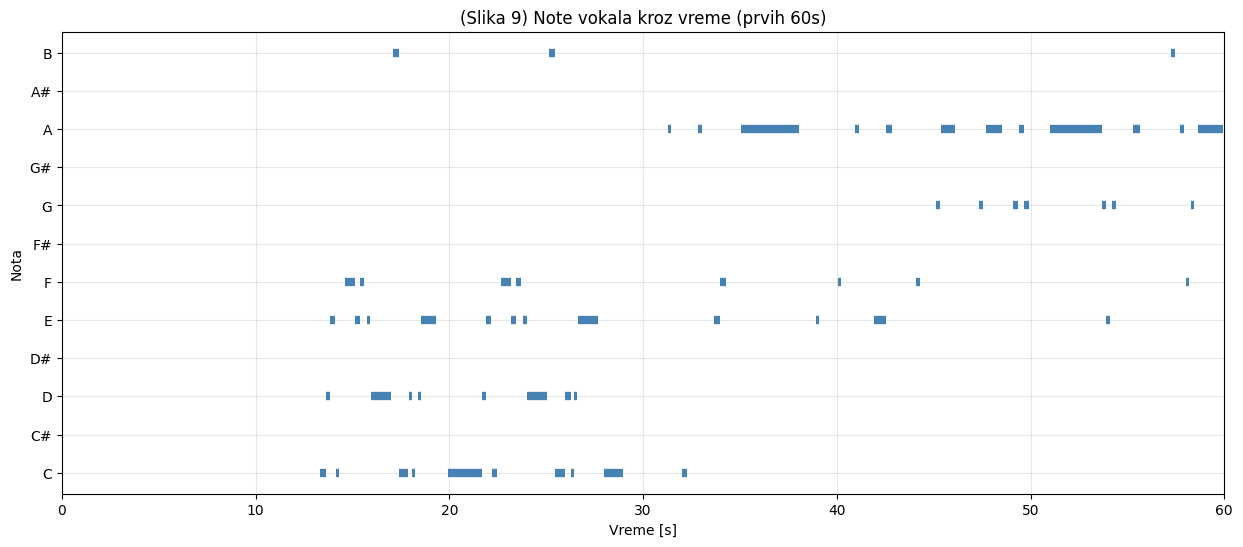

In [49]:
show_notes_timeline(
    merged_segments_vocals,
    notes,
    max_seconds=60,
    title='(Slika 9) Note vokala kroz vreme (prvih 60s)'
)

### 8.3.6. Reprodukcija vokala uz sinhronizovan prikaz trenutne i sledeće note

Na isti način, ponovo se koristi funkcija `play_bass_with_notes` iz poglavlja 8.2.7, sa parametrom `label='vokala'` koji prilagođava ispisanu poruku o pokretanju reprodukcije (npr. „Pokrećem reprodukciju vokala...” umesto „...bas-a...”), bez potrebe za izmenom same logike funkcije.

In [51]:
play_bass_with_notes(
    vocals_mono,
    sr,
    merged_segments_vocals,
    notes,
    label='vokala'
)

Output()

# 9. Zaključak

U ovom radu je, korak po korak, demonstriran kompletan proces ekstrakcije i analize muzičkih elemenata iz audio signala, počevši od sirovog `.wav` fajla, preko frekvencijske analize (STFT, spektrogram), razdvajanja izvora zvuka (Demucs, HPSS), ritmičke analize (onset detekcija, procena BPM-a), harmonijske analize (chroma obeležja, Krumhansl–Schmuckler detekcija tonaliteta), do praktične, interaktivne primene u vidu prikaza konkretnih nota izolovanog basa i vokala u realnom vremenu, sinhronizovano sa reprodukcijom pesme.

Kroz rad su se, u više navrata, poredili klasični pristupi obrade signala (HPSS, K-S algoritam, ručno definisani pragovi RMS energije) sa savremenim pristupima zasnovanim na dubokom učenju (Demucs), pri čemu se pokazalo da razdvajanje izvora zvuka, bilo klasičnim, bilo neuronskim putem, dosledno poboljšava kvalitet i preciznost svih narednih koraka analize (chroma prikaza, detekcije tonaliteta, prepoznavanja konkretnih nota) u odnosu na analizu sprovedenu direktno nad mešanim, nerazdvojenim signalom pesme. Ovo je i intuitivno očekivan rezultat, jer izolovanjem pojedinačnog instrumenta uklanja se „harmonijski i ritmički šum” koji unose svi ostali, istovremeno prisutni instrumenti u originalnom snimku.

Poslednje poglavlje rada, koje kombinuje chroma obeležja sa RMS energijom radi filtriranja šuma i prepoznavanja konkretnih odsviranih nota u realnom vremenu, ilustruje kako se prethodno objašnjeni teorijski koncepti mogu iskoristiti za izgradnju konkretnog, praktično upotrebljivog alata, u ovom slučaju, alata koji muzičaru može pomoći da po sluhu, bez notnog materijala, nauči bas ili vokalnu liniju neke pesme *(McFee et al, 2015)*.

### Mogući pravci daljeg razvoja

Kao moguća unapređenja pristupa opisanog u ovom radu, mogu se navesti:

- Automatska detekcija praga RMS energije (`silence_threshold_db`) po pesmi, umesto fiksne vrednosti, radi robusnijeg razdvajanja tišine od stvarnog sviranja u pesmama različitog nivoa produkcije i dinamike.
- Detekcija ne samo dominantne note po frame-u, već i **oktave** u kojoj je nota odsvirana (chroma obeležje po definiciji tu informaciju odbacuje), što bi zahtevalo korišćenje pune, oktavno-osetljive spektralne informacije umesto chroma reprezentacije.
- Proširenje interaktivnog prikaza nota i na ostale izolovane instrumente.

# 10. Literatura

1. [**Fernández-Sotos, A., Fernández-Caballero, A., & Latorre, J. M. (2016).** Influence of tempo and rhythmic unit in musical emotion regulation. Frontiers in Computational Neuroscience, 10, Article 80.](https://doi.org/10.3389/fncom.2016.00080)

2. [**Vigl, J., Koehler, F., & Henning, H. (2024).** Exploring the accuracy of musical tempo memory: The effects of reproduction method, reference tempo, and musical expertise. Memory & Cognition, 52, 1299–1312.](https://doi.org/10.3758/s13421-024-01543-6)

3. [**Shannon, C. E. (1949).** Communication in the presence of noise. Proceedings of the IRE, 37(1), 10–21.](https://doi.org/10.1109/JRPROC.1949.232969)

4. [**Allen, J. B., & Rabiner, L. R. (1977).** A unified approach to short-time Fourier analysis and synthesis. Proceedings of the IEEE, 65(11), 1558–1564.](https://doi.org/10.1109/PROC.1977.10770)

5. [**Défossez, A. (2021).** Hybrid Spectrogram and Waveform Source Separation. ISMIR 2021.](https://arxiv.org/abs/2111.03600)

6. [**McFee, B., Raffel, C., Liang, D., Ellis, D. P. W., McVicar, M., Battenberg, E., & Nieto, O. (2015).** librosa: Audio and music signal analysis in Python. Proceedings of the 14th Python in Science Conference, 18–25.](https://doi.org/10.25080/Majora-7b98e3ed-003)

7. [**Böck, S., Krebs, F., & Widmer, G. (2012).** Evaluating the online capabilities of onset detection methods. ISMIR.](https://archives.ismir.net/ismir2012/paper/000113.pdf)

8. **Krumhansl, C. L. (1990).** Cognitive Foundations of Musical Pitch. Oxford University Press.

9. [**Smith, J. O. (2011).** Spectral Audio Signal Processing. W3K Publishing.](https://ccrma.stanford.edu/~jos/sasp/)

10. [**Harris, C. R., et al. (2020).** Array programming with NumPy. Nature, 585, 357–362.](https://doi.org/10.1038/s41586-020-2649-2)

11. [**McKinney, W. (2010).** Data structures for statistical computing in Python.](https://doi.org/10.25080/Majora-92bf1922-00a)

12. [**Paszke, A., et al. (2019).** PyTorch: An imperative style, high-performance deep learning library.](https://papers.nips.cc/paper_files/paper/2019/hash/bdbca288fee7f92f2bfa9f7012727740-Abstract.html)

13. **Oppenheim, A. V., & Schafer, R. W. (2010).** Discrete-Time Signal Processing (3rd ed.). Pearson.

14. [**Nickolls, J., Buck, I., Garland, M., & Skadron, K. (2008).** Scalable parallel programming with CUDA. Queue, 6(2), 40–53.](https://doi.org/10.1145/1365490.1365500)

15. [**Peeters, G. (2007).** Template-based estimation of time-varying tempo. EURASIP Journal on Advances in Signal Processing.](https://doi.org/10.1155/2007/62874)

16. [**Willmott, C. J., & Matsuura, K. (2005).** Advantages of the mean absolute error (MAE) over the root mean square error (RMSE). Climate Research, 30, 79–82.](https://doi.org/10.3354/cr030079)

17. **Kuncheva, L. I. (2004).** Combining Pattern Classifiers. Wiley.

18. [**Dietterich, T. G. (2000).** Ensemble methods in machine learning. Lecture Notes in Computer Science, 1857, 1–15.](https://doi.org/10.1007/3-540-45014-9_1)

19. [**Fitzgerald, D. (2010).** Harmonic/Percussive Separation using Median Filtering. Proceedings of the 13th International Conference on Digital Audio Effects (DAFx-10), Graz, Austria.](https://dafx10.iem.at/papers/Dafx10/DAFx10_Paper_45.pdf)